## Problem Statement

### Business Context

Business communities in the United States are facing high demand for human resources, but one of the constant challenges is identifying and attracting the right talent, which is perhaps the most important element in remaining competitive. Companies in the United States look for hard-working, talented, and qualified individuals both locally as well as abroad.

The Immigration and Nationality Act (INA) of the US permits foreign workers to come to the United States to work on either a temporary or permanent basis. The act also protects US workers against adverse impacts on their wages or working conditions by ensuring US employers' compliance with statutory requirements when they hire foreign workers to fill workforce shortages. The immigration programs are administered by the Office of Foreign Labor Certification (OFLC).

OFLC processes job certification applications for employers seeking to bring foreign workers into the United States and grants certifications in those cases where employers can demonstrate that there are not sufficient US workers available to perform the work at wages that meet or exceed the wage paid for the occupation in the area of intended employment.

### Objective

In FY 2016, the OFLC processed 775,979 employer applications for 1,699,957 positions for temporary and permanent labor certifications. This was a nine percent increase in the overall number of processed applications from the previous year. The process of reviewing every case is becoming a tedious task as the number of applicants is increasing every year.

The increasing number of applicants every year calls for a Machine Learning based solution that can help in shortlisting the candidates having higher chances of VISA approval. OFLC has hired the firm EasyVisa for data-driven solutions. You as a data  scientist at EasyVisa have to analyze the data provided and, with the help of a classification model:

* Facilitate the process of visa approvals.
* Recommend a suitable profile for the applicants for whom the visa should be certified or denied based on the drivers that significantly influence the case status.

### Data Description

The data contains the different attributes of employee and the employer. The detailed data dictionary is given below.

* case_id: ID of each visa application
* continent: Information of continent the employee
* education_of_employee: Information of education of the employee
* has_job_experience: Does the employee has any job experience? Y= Yes; N = No
* requires_job_training: Does the employee require any job training? Y = Yes; N = No
* no_of_employees: Number of employees in the employer's company
* yr_of_estab: Year in which the employer's company was established
* region_of_employment: Information of foreign worker's intended region of employment in the US.
* prevailing_wage:  Average wage paid to similarly employed workers in a specific occupation in the area of intended employment. The purpose of the prevailing wage is to ensure that the foreign worker is not underpaid compared to other workers offering the same or similar service in the same area of employment.
* unit_of_wage: Unit of prevailing wage. Values include Hourly, Weekly, Monthly, and Yearly.
* full_time_position: Is the position of work full-time? Y = Full Time Position; N = Part Time Position
* case_status:  Flag indicating if the Visa was certified or denied

## Installing and Importing the necessary libraries

In [1]:
# Installing the libraries with the specified version.
#!pip install numpy==2.4.6 pandas==2.3.3 scikit-learn==1.9.0 matplotlib==3.11.0 seaborn==0.13.2 imbalanced-learn==0.14.2 statsmodels==0.14.6 scipy==1.18.1 xgboost==2.0.3 -q --user


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# To impute missing values
import scipy
import sklearn

from sklearn.impute import SimpleImputer
# To scale the data, do one-hot encoding
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# To split data into train and test
from sklearn.model_selection import train_test_split
# To create k folds of data and get cross validation score
from sklearn.model_selection import KFold, cross_val_score
# To do hyperparameter tuning
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV

# To undersample and oversample the data
from imblearn.over_sampling  import SMOTE
from imblearn.under_sampling import RandomUnderSampler

# Models
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier
from sklearn.ensemble import AdaBoostClassifier, GradientBoostingClassifier
import xgboost
from xgboost import XGBClassifier

# Performance Evaluation Metrics
from sklearn.metrics import (
    make_scorer,
    accuracy_score,
    recall_score,
    precision_score,
    f1_score,
    confusion_matrix
)

# To suppress scientific notations
pd.set_option("display.float_format", lambda x: "%.3f" % x)
# To supress warnings
import warnings

warnings.filterwarnings("ignore")

In [3]:
print(f"np: {np.__version__}")
print(f"pd: {pd.__version__}")
print(f"sns: {sns.__version__}")
print(f"sklearn: {sklearn.__version__}")
print(f"scipy: {scipy.__version__}")
print(f"xgboost: {xgboost.__version__}")

np: 2.4.6
pd: 2.3.3
sns: 0.13.2
sklearn: 1.9.0
scipy: 1.18.1
xgboost: 2.0.3


**Note**: *After running the above cell, kindly restart the notebook kernel and run all cells sequentially from the below.*

In [4]:
#from google.colab import drive
#drive.mount('/content/drive')

## Import Dataset

In [5]:
# Load the dataset
# df_orig = pd.read_csv('/content/drive/MyDrive/AIML-Projects/Project3-AdvancedML-EasyVisa/Project3-UKS-Solution/EasyVisa.csv')
df_orig = pd.read_csv("../data/raw_data/EasyVisa.csv")

In [6]:
df = df_orig.copy()

## Overview of the Dataset

#### View the first and last 5 rows of the dataset

In [7]:
df.head()

,case_id,continent,education_of_employee,has_job_experience,requires_job_training,no_of_employees,yr_of_estab,region_of_employment,prevailing_wage,unit_of_wage,full_time_position,case_status
0,EZYV01,Asia,High School,N,N,14513,2007,West,592.203,Hour,Y,Denied
1,EZYV02,Asia,Master's,Y,N,2412,2002,Northeast,83425.650,Year,Y,Certified
2,EZYV03,Asia,Bachelor's,N,Y,44444,2008,West,122996.860,Year,Y,Denied
3,EZYV04,Asia,Bachelor's,N,N,98,1897,West,83434.030,Year,Y,Denied
4,EZYV05,Africa,Master's,Y,N,1082,2005,South,149907.390,Year,Y,Certified


In [8]:
df.tail()

,case_id,continent,education_of_employee,has_job_experience,requires_job_training,no_of_employees,yr_of_estab,region_of_employment,prevailing_wage,unit_of_wage,full_time_position,case_status
25475,EZYV25476,Asia,Bachelor's,Y,Y,2601,2008,South,77092.570,Year,Y,Certified
25476,EZYV25477,Asia,High School,Y,N,3274,2006,Northeast,279174.790,Year,Y,Certified
25477,EZYV25478,Asia,Master's,Y,N,1121,1910,South,146298.850,Year,N,Certified
25478,EZYV25479,Asia,Master's,Y,Y,1918,1887,West,86154.770,Year,Y,Certified
25479,EZYV25480,Asia,Bachelor's,Y,N,3195,1960,Midwest,70876.910,Year,Y,Certified


#### Understand the shape of the dataset

In [9]:
df.shape

(25480, 12)

#### Check the data types of the columns for the dataset

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25480 entries, 0 to 25479
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   case_id                25480 non-null  object 
 1   continent              25480 non-null  object 
 2   education_of_employee  25480 non-null  object 
 3   has_job_experience     25480 non-null  object 
 4   requires_job_training  25480 non-null  object 
 5   no_of_employees        25480 non-null  int64  
 6   yr_of_estab            25480 non-null  int64  
 7   region_of_employment   25480 non-null  object 
 8   prevailing_wage        25480 non-null  float64
 9   unit_of_wage           25480 non-null  object 
 10  full_time_position     25480 non-null  object 
 11  case_status            25480 non-null  object 
dtypes: float64(1), int64(2), object(9)
memory usage: 2.3+ MB


In [11]:
df.dtypes

case_id                   object
continent                 object
education_of_employee     object
has_job_experience        object
requires_job_training     object
no_of_employees            int64
yr_of_estab                int64
region_of_employment      object
prevailing_wage          float64
unit_of_wage              object
full_time_position        object
case_status               object
dtype: object

#### Observations on the Dataset

1. The dataset include 25480 records. Each record has 12 columns.
2. 9 objects are object type (categorical), and 3 of them are numerical data() 2 of them are integer type and one is float type variables.
3. 'case_status' is the target variable.
4. There appears tobe no missing values in tha data based on each column has 25480 non-null records.
5. 'no_of_employees' 
    a. Ranges between -26 to 602069. 
    b. There are some negative values in the data, which are probably mistakes in entering. This willbe be corrected later.
    c. median value is 2109. 50% of the records indicate no. of employees less than 2109.  
6. 'yr_of_estb'
    a. Ranges from 1800-2016
        b. 50% of the companies established earlier than 1997
7. 'prevailing_wage'
    a. Ranges from 2.1367 - 319210.27. This large variation is explained in the other column 'unit_of_wage' where the wage is either Hourly/Weekly/Monthly/Yearly.
    b. Probably, this data needs to be converted to consistent units (ex: Yearly) prior to performing the analysis.

## Exploratory Data Analysis (EDA)

#### Let's check the statistical summary of the data

In [12]:
df.describe()

,no_of_employees,yr_of_estab,prevailing_wage
count,25480.000,25480.000,25480.000
mean,5667.043,1979.410,74455.815
std,22877.929,42.367,52815.942
min,-26.000,1800.000,2.137
25%,1022.000,1976.000,34015.480
50%,2109.000,1997.000,70308.210
75%,3504.000,2005.000,107735.513
max,602069.000,2016.000,319210.270


#### Fixing the negative values in number of employees columns

In [13]:
(df['no_of_employees']<0).sum()

np.int64(33)

In [14]:
df['no_of_employees'] = np.abs(df['no_of_employees'])

In [15]:
(df['no_of_employees']<0).sum()

np.int64(0)

### Check the duplicates

In [16]:
df.duplicated().sum()

np.int64(0)

There are no duplicate values in the data.

### Let's check the count of each unique category in each of the categorical variables

In [17]:
cat_cols = df.select_dtypes(include = [ 'object', 'category']).columns.to_list()
cat_cols

['case_id',
 'continent',
 'education_of_employee',
 'has_job_experience',
 'requires_job_training',
 'region_of_employment',
 'unit_of_wage',
 'full_time_position',
 'case_status']

In [18]:
for col in cat_cols:
  print(f"Count:{col}   Unique#:{df[col].nunique()}")
  print(df[col].value_counts(normalize=True)*100, "\n")

Count:case_id   Unique#:25480
case_id
EZYV01      0.004
EZYV02      0.004
EZYV03      0.004
EZYV04      0.004
EZYV05      0.004
             ... 
EZYV25476   0.004
EZYV25477   0.004
EZYV25478   0.004
EZYV25479   0.004
EZYV25480   0.004
Name: proportion, Length: 25480, dtype: float64 

Count:continent   Unique#:6
continent
Asia            66.173
Europe          14.647
North America   12.920
South America    3.344
Africa           2.162
Oceania          0.754
Name: proportion, dtype: float64 

Count:education_of_employee   Unique#:4
education_of_employee
Bachelor's    40.165
Master's      37.810
High School   13.422
Doctorate      8.603
Name: proportion, dtype: float64 

Count:has_job_experience   Unique#:2
has_job_experience
Y   58.093
N   41.907
Name: proportion, dtype: float64 

Count:requires_job_training   Unique#:2
requires_job_training
N   88.403
Y   11.597
Name: proportion, dtype: float64 

Count:region_of_employment   Unique#:5
region_of_employment
Northeast   28.238
South      

In [19]:
df.head()

,case_id,continent,education_of_employee,has_job_experience,requires_job_training,no_of_employees,yr_of_estab,region_of_employment,prevailing_wage,unit_of_wage,full_time_position,case_status
0,EZYV01,Asia,High School,N,N,14513,2007,West,592.203,Hour,Y,Denied
1,EZYV02,Asia,Master's,Y,N,2412,2002,Northeast,83425.650,Year,Y,Certified
2,EZYV03,Asia,Bachelor's,N,Y,44444,2008,West,122996.860,Year,Y,Denied
3,EZYV04,Asia,Bachelor's,N,N,98,1897,West,83434.030,Year,Y,Denied
4,EZYV05,Africa,Master's,Y,N,1082,2005,South,149907.390,Year,Y,Certified


### Columns with numerical values as data

In [20]:
num_cols = df.select_dtypes(include="number").columns.to_list()
num_cols

['no_of_employees', 'yr_of_estab', 'prevailing_wage']

#### Convert the prevailing wages to consistent units, i.e. Yearly salaries

In [21]:
def salary(row):
    unit = row["unit_of_wage"]
    wage = row["prevailing_wage"]
    if unit == "Hour":
        return wage * 52 * 40
    elif unit == "Week":
        return wage * 52
    elif unit == "Month":
        return wage * 12
    else:
        return wage

df["yearly_salary"] = df.apply(salary, axis=1)
df[["prevailing_wage", "unit_of_wage", "yearly_salary"]]

,prevailing_wage,unit_of_wage,yearly_salary
0,592.203,Hour,1231782.032
1,83425.650,Year,83425.650
2,122996.860,Year,122996.860
3,83434.030,Year,83434.030
4,149907.390,Year,149907.390
...,...,...,...
25475,77092.570,Year,77092.570
25476,279174.790,Year,279174.790
25477,146298.850,Year,146298.850
25478,86154.770,Year,86154.770


In [22]:
df.shape

(25480, 13)

### Univariate Analysis

In [23]:
def histogram_boxplot(data, feature, figsize=(15, 10), kde=False, bins=None):
    """
    Boxplot and histogram combined

    data: dataframe
    feature: dataframe column
    figsize: size of figure (default (15,10))
    kde: whether to show the density curve (default False)
    bins: number of bins for histogram (default None)
    """
    f2, (ax_box2, ax_hist2) = plt.subplots(
        nrows=2,  # Number of rows of the subplot grid= 2
        sharex=True,  # x-axis will be shared among all subplots
        gridspec_kw={"height_ratios": (0.25, 0.75)},
        figsize=figsize,
    )  # creating the 2 subplots
    sns.boxplot(
        data=data, x=feature, ax=ax_box2, showmeans=True, color="violet"
    )  # boxplot will be created and a triangle will indicate the mean value of the column
    sns.histplot(
        data=data, x=feature, kde=kde, ax=ax_hist2, bins=bins
    ) if bins else sns.histplot(
        data=data, x=feature, kde=kde, ax=ax_hist2
    )  # For histogram
    ax_hist2.axvline(
        data[feature].mean(), color="green", linestyle="--"
    )  # Add mean to the histogram
    ax_hist2.axvline(
        data[feature].median(), color="black", linestyle="-"
    )  # Add median to the histogram

In [24]:
# function to create labeled barplots


def labeled_barplot(data, feature, perc=False, n=None):
    """
    Barplot with percentage at the top

    data: dataframe
    feature: dataframe column
    perc: whether to display percentages instead of count (default is False)
    n: displays the top n category levels (default is None, i.e., display all levels)
    """

    total = len(data[feature])  # length of the column
    count = data[feature].nunique()
    if n is None:
        plt.figure(figsize=(count + 1, 5))
    else:
        plt.figure(figsize=(n + 1, 5))

    plt.xticks(rotation=90, fontsize=15)
    ax = sns.countplot(
        data=data,
        x=feature,
        palette="Paired",
        order=data[feature].value_counts().index[:n].sort_values(),
    )

    for p in ax.patches:
        if perc == True:
            label = "{:.1f}%".format(
                100 * p.get_height() / total
            )  # percentage of each class of the category
        else:
            label = p.get_height()  # count of each level of the category

        x = p.get_x() + p.get_width() / 2  # width of the plot
        y = p.get_height()  # height of the plot

        ax.annotate(
            label,
            (x, y),
            ha="center",
            va="center",
            size=12,
            xytext=(0, 5),
            textcoords="offset points",
        )  # annotate the percentage

    plt.show()  # show the plot

#### Observations on education of employee

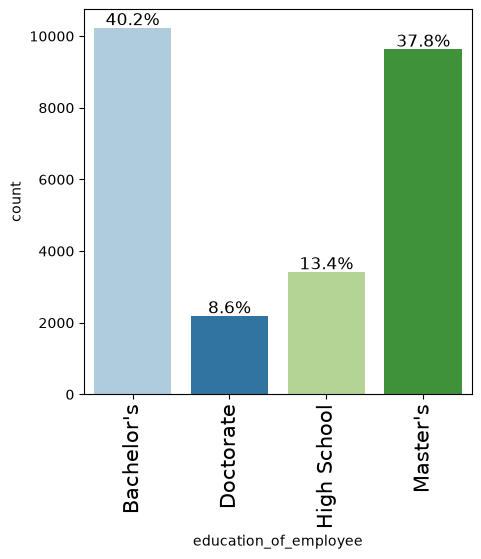

In [25]:
labeled_barplot(df, 'education_of_employee', perc=True)

There are only 8.6%  profiles with Doctorate whereas 40.2% with Bachelor's and 37.8% with Master's. 13.4% have HighSchool diploma.

#### Observations on region of employment

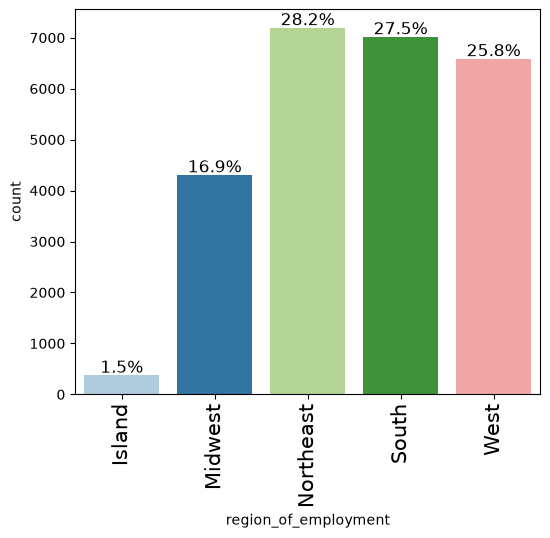

In [26]:
labeled_barplot(df, 'region_of_employment', perc=True)

28.2% of the profiles listed Northeast region as the 'region_of_employment' whereas only 1.5% have Island as the region of employment. 

#### Observations on job experience

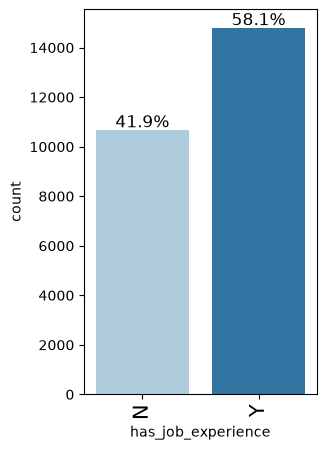

In [27]:
labeled_barplot(df, 'has_job_experience', perc=True)

58.1% profiles have listed 'has_job_experience' while remaining 41.9% don't have job experience.

#### Observations on case status

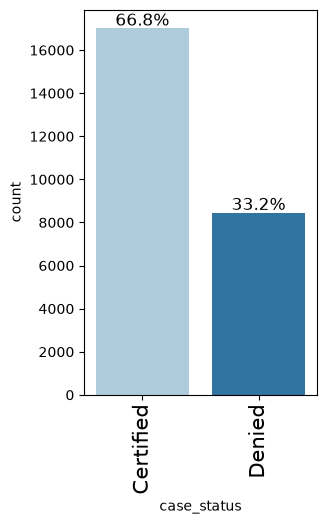

In [28]:
labeled_barplot(df, 'case_status', perc=True)

'case_status' is the target variable. Data is imbalanced as 66.8% are certified for VISA and 33.2% are Denied.

### Bivariate Analysis

**Creating functions that will help us with further analysis.**

In [29]:
### function to plot distributions wrt target


def distribution_plot_wrt_target(data, predictor, target):

    fig, axs = plt.subplots(2, 2, figsize=(12, 10))

    target_uniq = data[target].unique()

    axs[0, 0].set_title("Distribution of target for target=" + str(target_uniq[0]))
    sns.histplot(
        data=data[data[target] == target_uniq[0]],
        x=predictor,
        kde=True,
        ax=axs[0, 0],
        color="teal",
        stat="density",
    )

    axs[0, 1].set_title("Distribution of target for target=" + str(target_uniq[1]))
    sns.histplot(
        data=data[data[target] == target_uniq[1]],
        x=predictor,
        kde=True,
        ax=axs[0, 1],
        color="orange",
        stat="density",
    )

    axs[1, 0].set_title("Boxplot w.r.t target")
    sns.boxplot(data=data, x=target, y=predictor, ax=axs[1, 0], palette="gist_rainbow")

    axs[1, 1].set_title("Boxplot (without outliers) w.r.t target")
    sns.boxplot(
        data=data,
        x=target,
        y=predictor,
        ax=axs[1, 1],
        showfliers=False,
        palette="gist_rainbow",
    )

    plt.tight_layout()
    plt.show()

In [30]:
def stacked_barplot(data, predictor, target):
    """
    Print the category counts and plot a stacked bar chart

    data: dataframe
    predictor: independent variable
    target: target variable
    """
    count = data[predictor].nunique()
    sorter = data[target].value_counts().index[-1]
    tab1 = pd.crosstab(data[predictor], data[target], margins=True).sort_values(
        by=sorter, ascending=False
    )
    print(tab1)
    print("-" * 120)
    tab = pd.crosstab(data[predictor], data[target], normalize="index").sort_values(
        by=sorter, ascending=False
    )
    tab.plot(kind="bar", stacked=True, figsize=(count + 5, 5))
    plt.legend(
        loc="lower left", frameon=False,
    )
    plt.legend(loc="upper left", bbox_to_anchor=(1, 1))
    plt.show()

#### Does higher education increase the chances of visa certification for well-paid jobs abroad?

case_status            Certified  Denied    All
education_of_employee                          
All                        17018    8462  25480
Bachelor's                  6367    3867  10234
High School                 1164    2256   3420
Master's                    7575    2059   9634
Doctorate                   1912     280   2192
------------------------------------------------------------------------------------------------------------------------


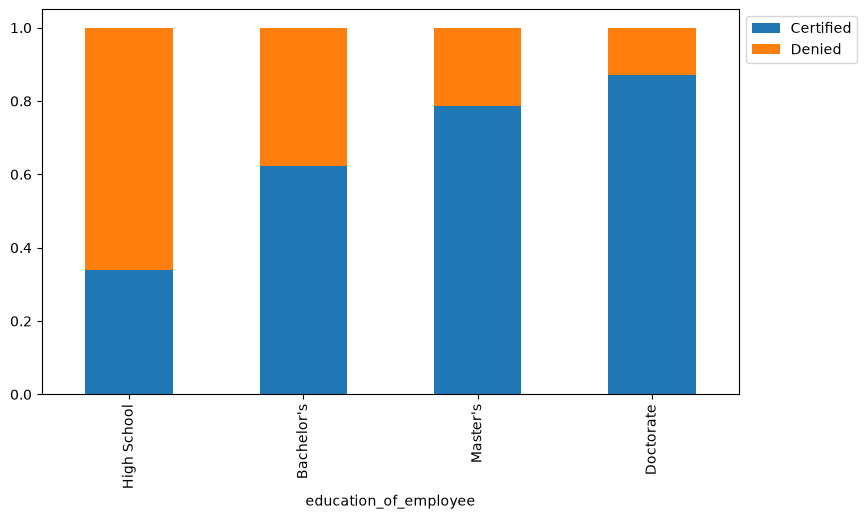

In [31]:
stacked_barplot(df, 'education_of_employee', 'case_status')

'edication_of_employee' shows some influence on whether he/she is Certified for VISA or Denied. Employess with higher education are more likely Certified for VISA and less likely to be denied. 

#### How does visa status vary across different continents?

case_status    Certified  Denied    All
continent                              
All                17018    8462  25480
Asia               11012    5849  16861
North America       2037    1255   3292
Europe              2957     775   3732
South America        493     359    852
Africa               397     154    551
Oceania              122      70    192
------------------------------------------------------------------------------------------------------------------------


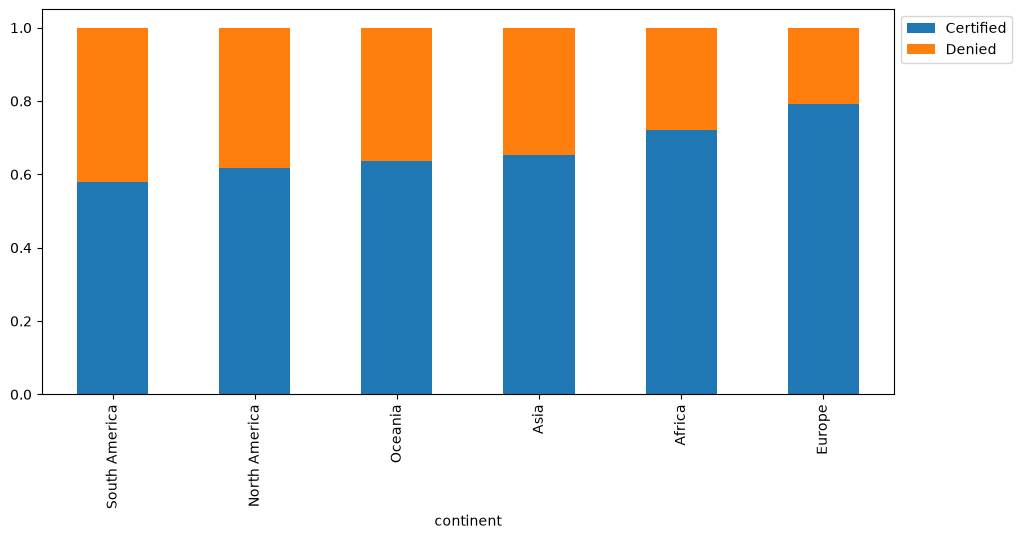

In [32]:
stacked_barplot(df, 'continent', 'case_status')

'continent' shows some influence on whether he/she is Certified for VISA or Denied. Employeses from Europe are more likely Certified for VISA and those from South America are less likely to be Certified. 

#### Does having prior work experience influence the chances of visa certification for career opportunities abroad?

case_status         Certified  Denied    All
has_job_experience                          
All                     17018    8462  25480
N                        5994    4684  10678
Y                       11024    3778  14802
------------------------------------------------------------------------------------------------------------------------


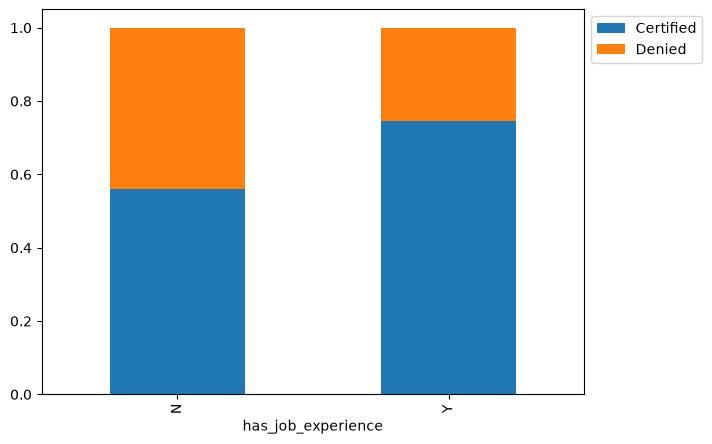

In [33]:
stacked_barplot(df, 'has_job_experience', 'case_status')

Emplooyees with prior job experience are more likely to be 'Certified' for VISA compared to those who do not have prior work experience.

#### Is the prevailing wage consistent across all regions of the US?

<Axes: xlabel='region_of_employment', ylabel='yearly_salary'>

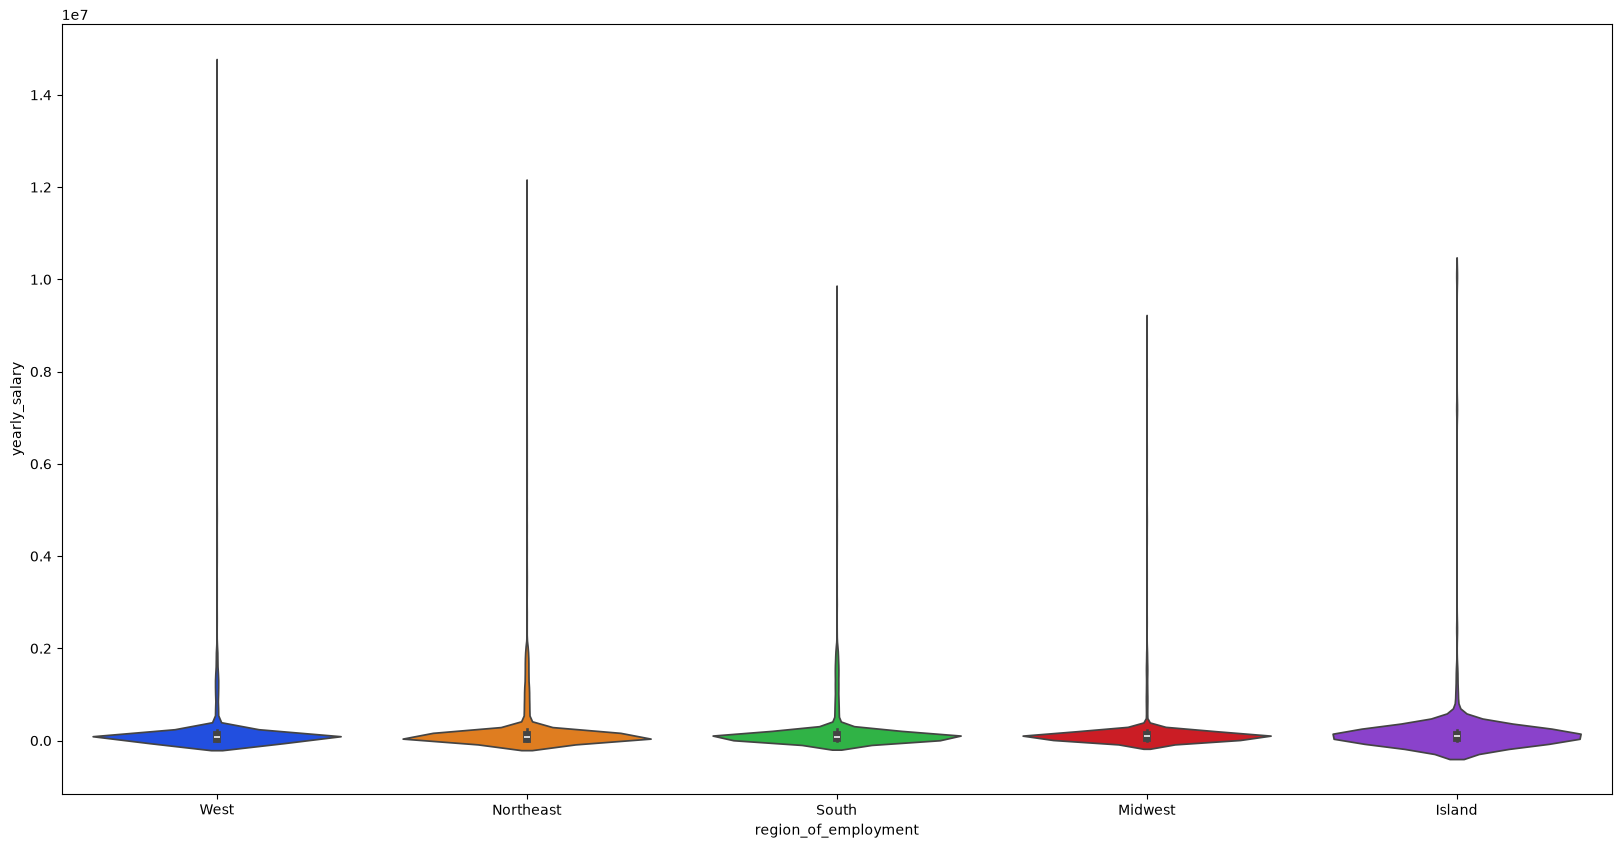

In [34]:
plt.figure(figsize=(20, 10))
sns.violinplot(
    data=df,
    x="region_of_employment",
    y="yearly_salary",
    palette="bright",
)

<Axes: xlabel='region_of_employment', ylabel='yearly_salary'>

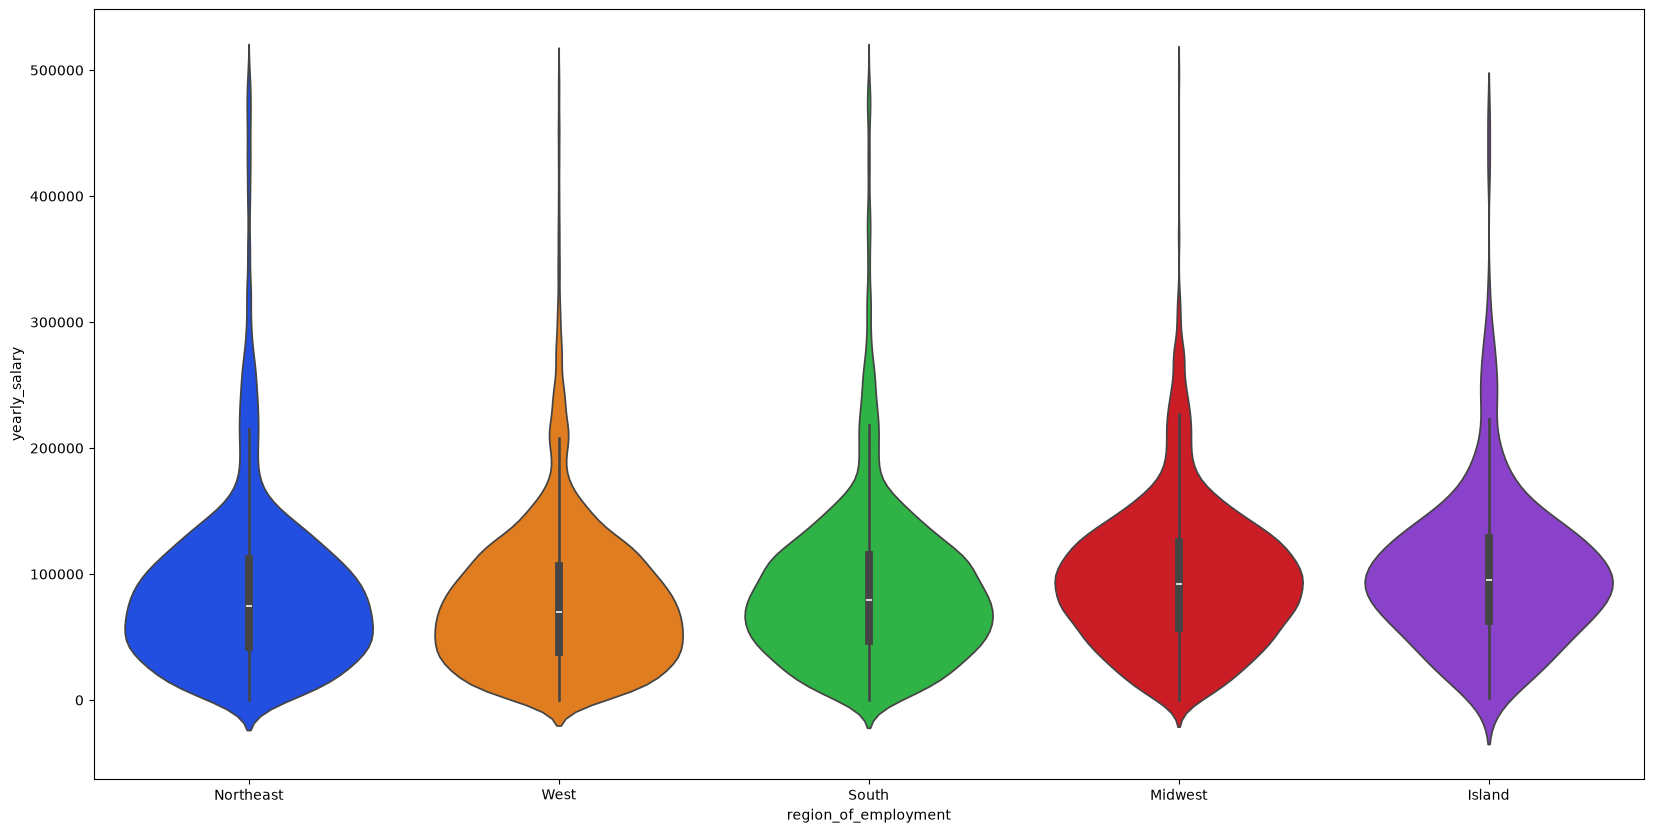

In [35]:
plt.figure(figsize=(20, 10))
sns.violinplot(data=df[df['yearly_salary']<500000], x="region_of_employment", y="yearly_salary", palette="bright")

Median yearly salary of the employees is mostly similar regardless of the region of employment. Data from every region has large number of outliers. Barring outliers, the prevailing wage appears to be consistent across all regions of employment. 

unit_of_wage          Hour  Month  Week   Year    All
region_of_employment                                 
All                   2157     89   272  22962  25480
Northeast              865     29    92   6209   7195
South                  696     28    68   6225   7017
West                   432     19    77   6058   6586
Midwest                146     13    32   4116   4307
Island                  18      0     3    354    375
------------------------------------------------------------------------------------------------------------------------


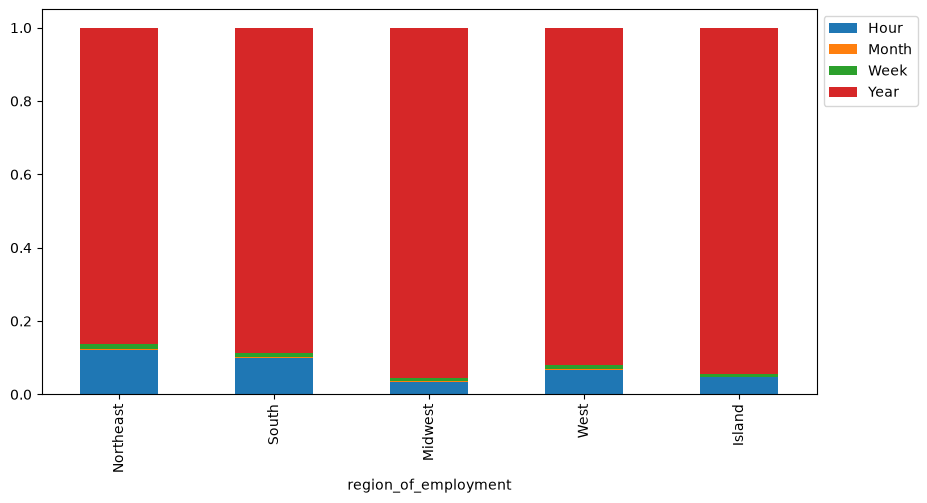

In [36]:
stacked_barplot(df, "region_of_employment", "unit_of_wage")

Moreover, majority of the applicants receive yearly wage across all the regions.

#### Does the unit of prevailing wage (Hourly, Weekly, etc.) have any impact on the likelihood of visa application certification?

case_status   Certified  Denied    All
unit_of_wage                          
All               17018    8462  25480
Year              16047    6915  22962
Hour                747    1410   2157
Week                169     103    272
Month                55      34     89
------------------------------------------------------------------------------------------------------------------------


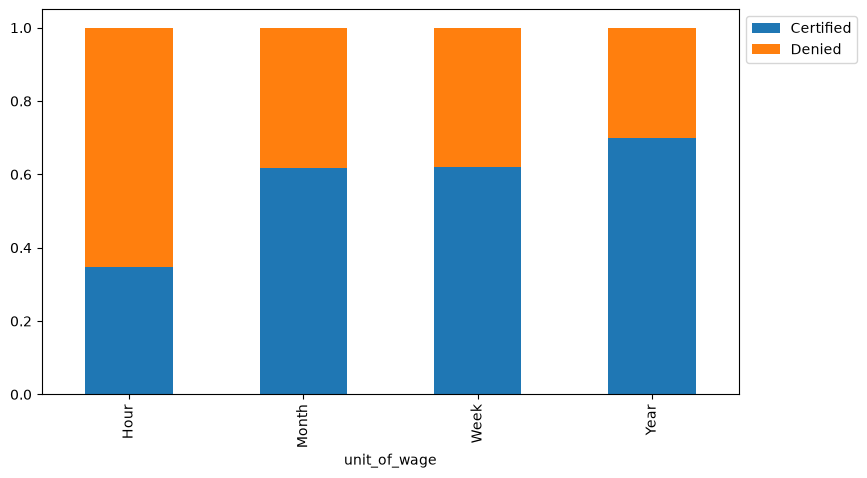

In [37]:
stacked_barplot(df, 'unit_of_wage', 'case_status')

Employees with hourly wages are less likely to be certified compared to those with yearly salary. There may not be significant difference between the chances of VISA approval for those with monthly and weekly wages.

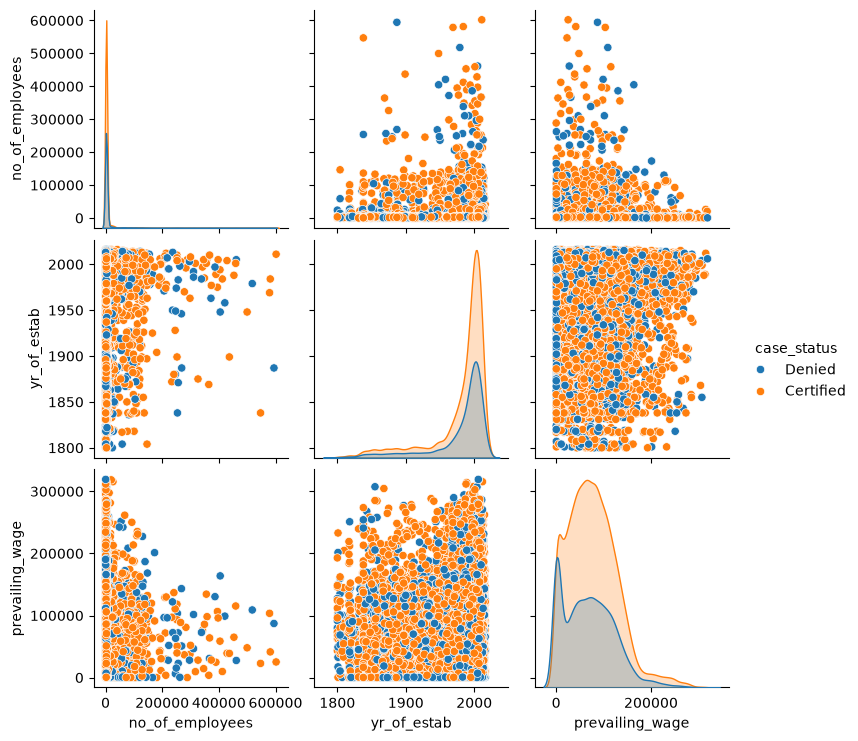

In [38]:
sns.pairplot(df, vars = num_cols, diag_kind='kde', hue='case_status')

There appears to be no correlation among the numerical variables.

<Axes: >

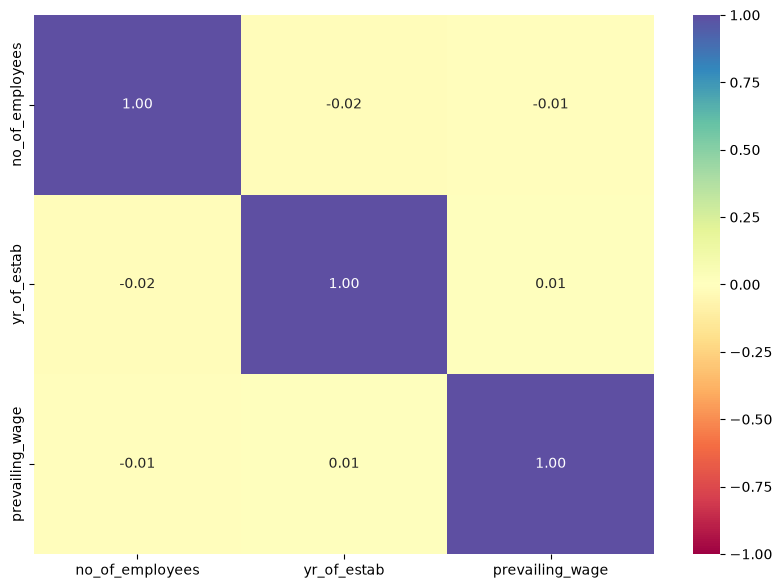

In [39]:
plt.figure(figsize=(10, 7))
# HeatMap showing correlation
sns.heatmap(
    df[num_cols].corr(), vmin=-1, vmax=1, annot=True, fmt="0.2f", cmap="Spectral"
)

## Data Pre-processing

In [40]:
df.columns

Index(['case_id', 'continent', 'education_of_employee', 'has_job_experience',
       'requires_job_training', 'no_of_employees', 'yr_of_estab',
       'region_of_employment', 'prevailing_wage', 'unit_of_wage',
       'full_time_position', 'case_status', 'yearly_salary'],
      dtype='object')

In [41]:
df.shape

(25480, 13)

### Outlier Check

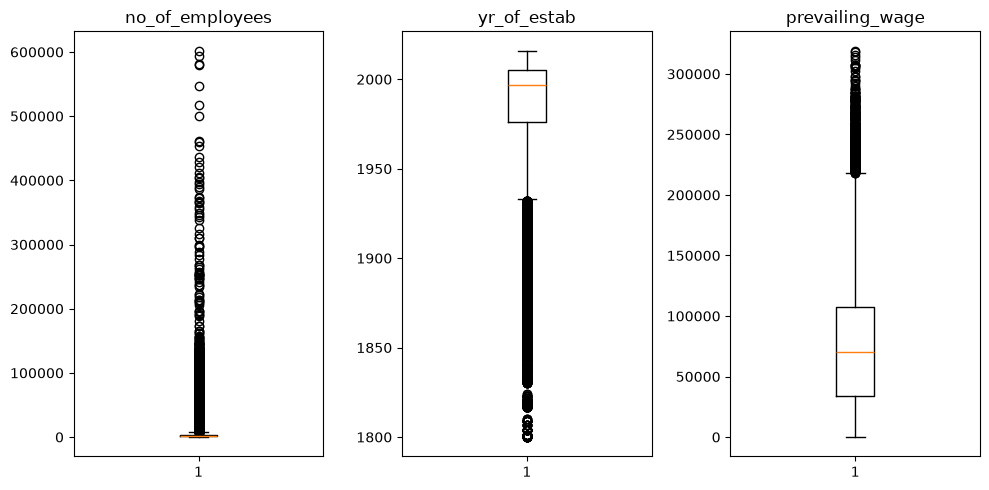

In [42]:
plt.figure(figsize=(10, 5))

for i, variable in enumerate(num_cols):
    plt.subplot(1, 3, i + 1)
    plt.boxplot(df[variable], whis=1.5)
    plt.tight_layout()
    plt.title(variable)

plt.show()

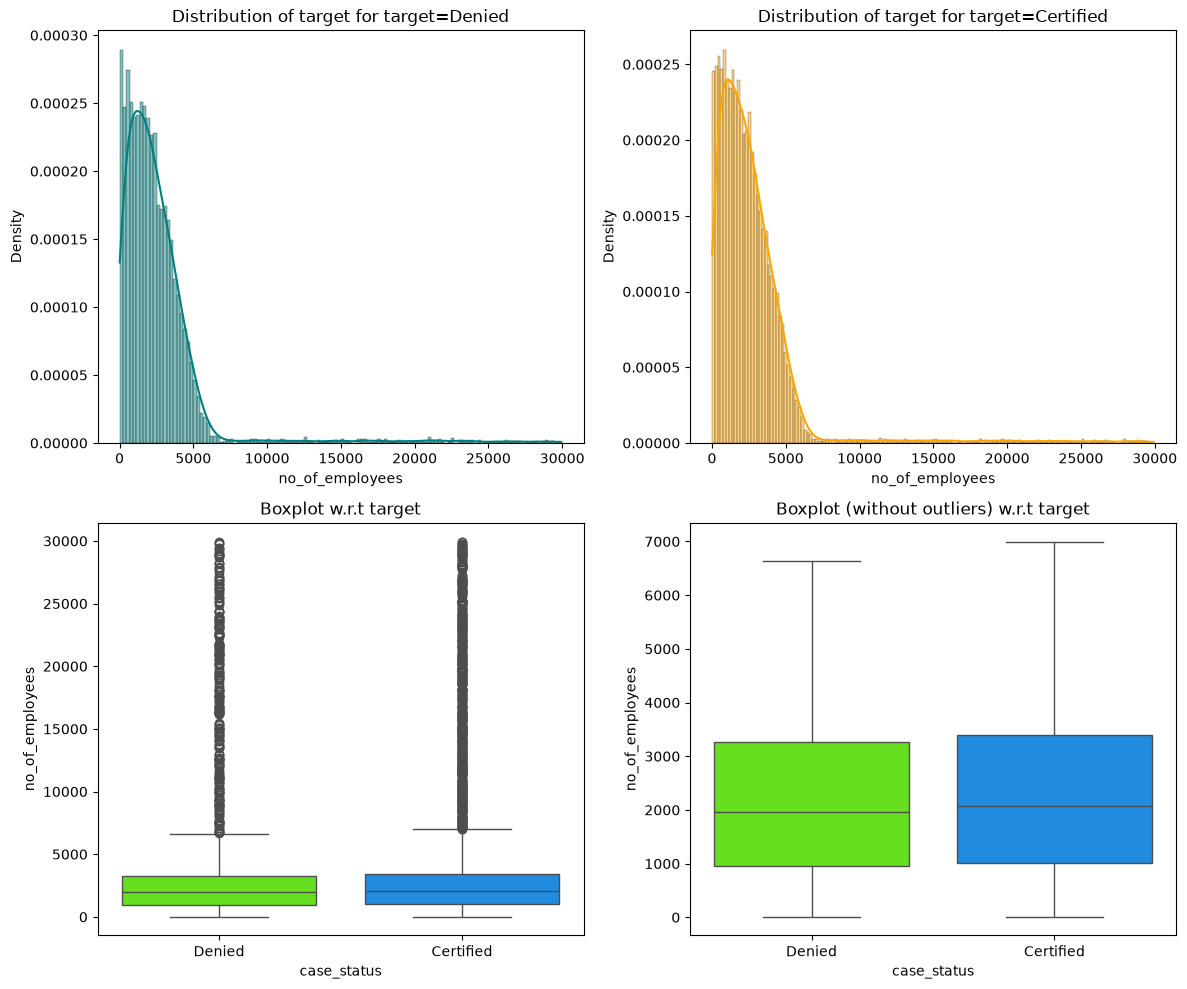

In [43]:
distribution_plot_wrt_target(
    df[df["no_of_employees"] < 30000], "no_of_employees", "case_status"
)

The data of 'no_of_employees' is highly right skewed. There are lot of outliers in both the 'Certified' and 'Denied' classes. 'no_of_employees'  does not appear to have a significant influence on the prediction of 'case_status' class. This can be verified later by feature imporances.

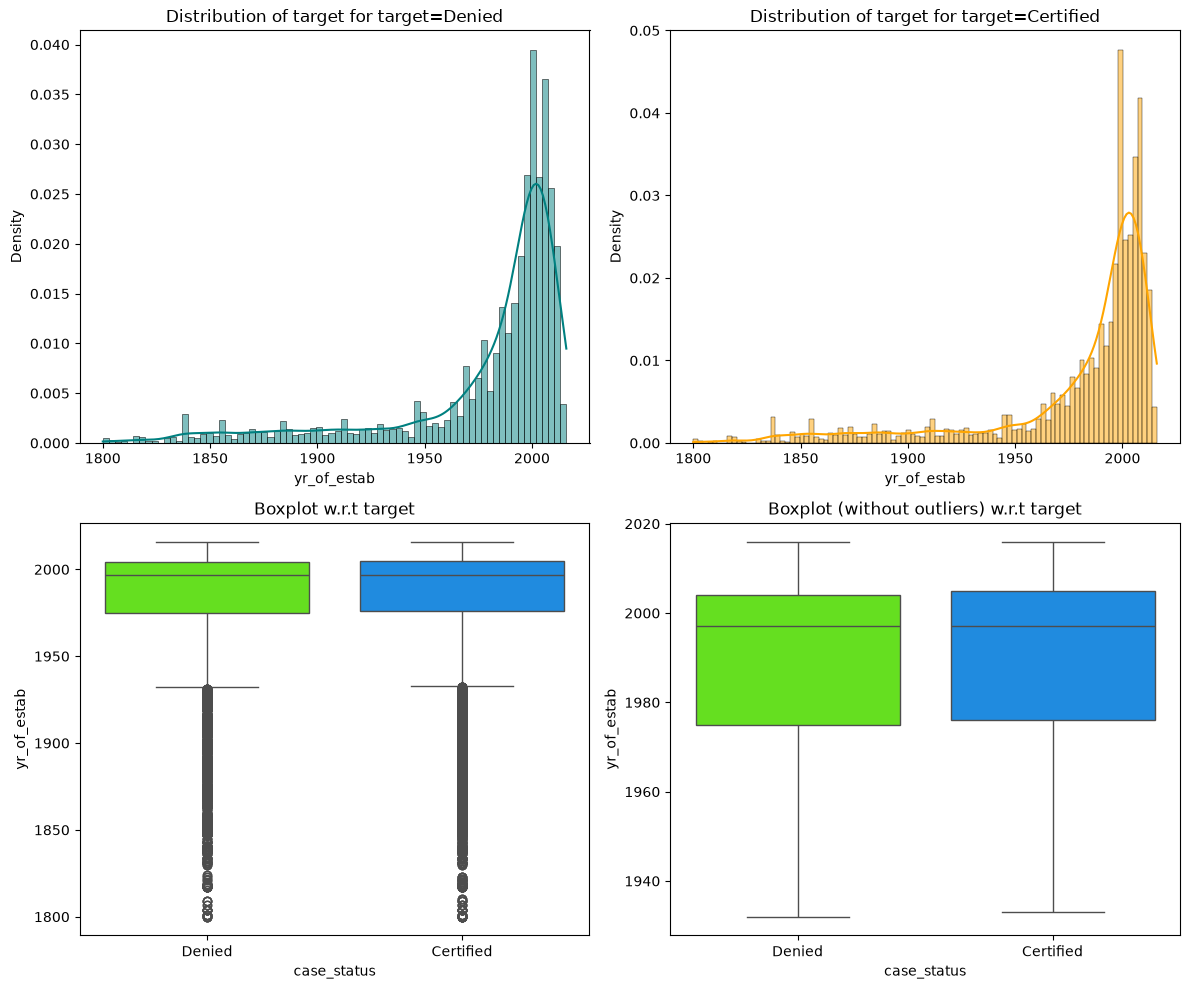

In [44]:
distribution_plot_wrt_target(df, "yr_of_estab", "case_status")

The data of 'yr_of_estab' is highly left skewed. There are lot of outliers in both the 'Certified' and 'Denied' classes. 'yr_of_estab'  does not appear to have a significant influence on the prediction of 'case_status' class. This can be verified later by feature imporances.

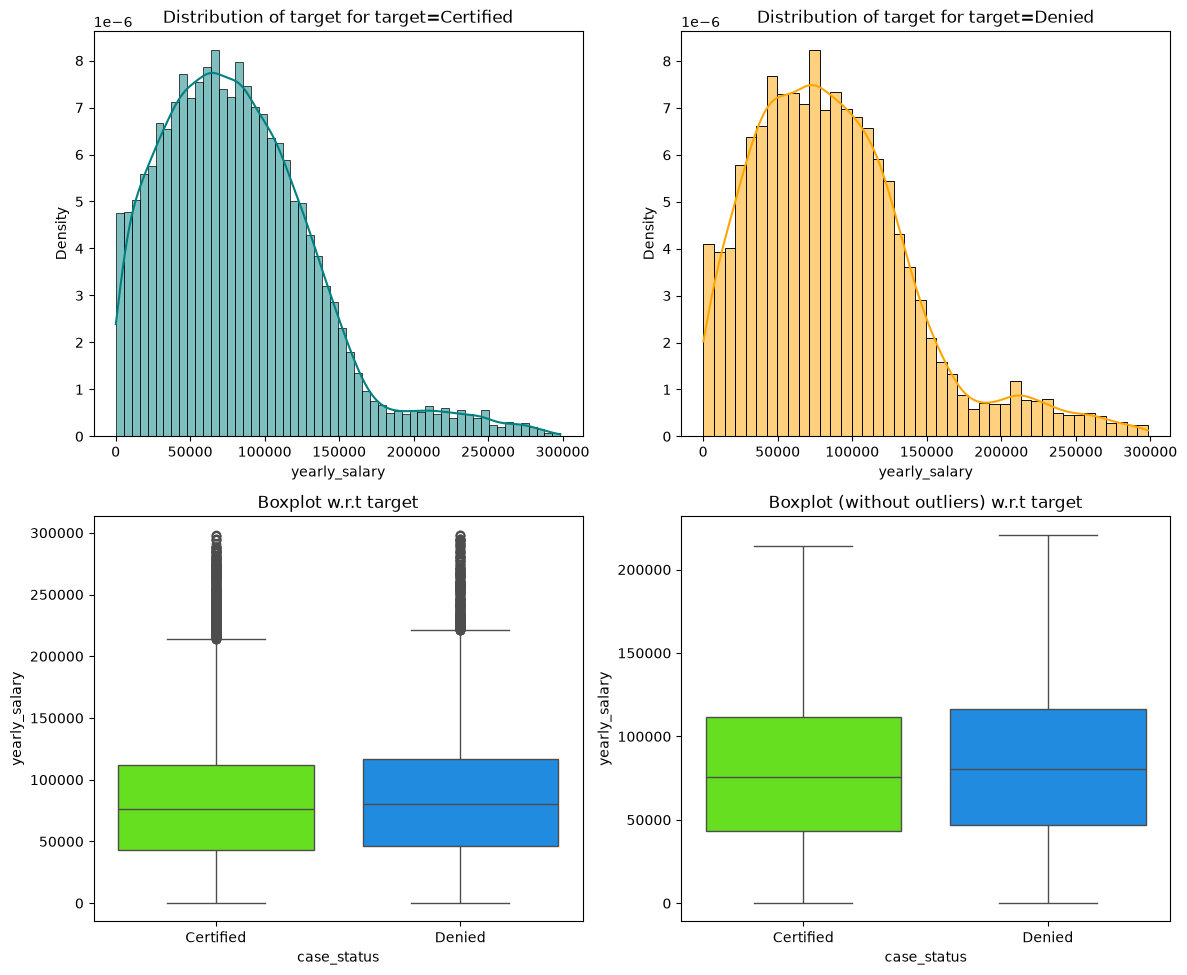

In [45]:
distribution_plot_wrt_target(
    df[df["yearly_salary"] < 300000], "yearly_salary", "case_status"
)

The data of 'prevailing_wage' is highly right skewed. There are lot of outliers in both the 'Certified' and 'Denied' classes. 'prevailing_wage'  does not appear to have a significant influence on the prediction of 'case_status' class. This can be verified later by feature imporances.

### Data Preparation for modeling

#### Drop Variables that are not important for the analysis

In [46]:
# case_id is unique for each record. It does not add any value to the analysis. Hence dropping this variable.
df1 = df.copy()
df = df.drop("case_id", axis=1)
df.shape

(25480, 12)

In [47]:
# prevailing_wage and yearly_salary will be highly correlated as yearly_salary is nothing but the prevailing_wage in consistent units. Hence, overwriting  prevailing_wage with yearly_salary and dropping yearly_salary from the analysis.
df2 = df.copy()
df['prevailing_wage'] = df['yearly_salary']
df = df.drop("yearly_salary", axis=1)
df.shape

(25480, 11)

### Separate Independent and Dependent Variables

In [48]:
X = df.drop(["case_status"], axis=1)
y = df["case_status"].apply(lambda x: 1 if x == "Certified" else 0)

### Split the data into train, validation and test sets

In [49]:
# Splitting data into training, validation and test set:
# first we split data into 2 parts, say temporary and test

X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.2, random_state=1, stratify=y
)

# then we split the temporary set into train and validation

X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.25, random_state=1, stratify=y_temp
)
print(X_train.shape, X_val.shape, X_test.shape)

(15288, 10) (5096, 10) (5096, 10)


In [50]:
cat_cols = X.select_dtypes(include=["object", "category"]).columns.to_list()
for i in cat_cols:
    print(X[i].value_counts(normalize=True)*100)
    print("_" * 30)

continent
Asia            66.173
Europe          14.647
North America   12.920
South America    3.344
Africa           2.162
Oceania          0.754
Name: proportion, dtype: float64
______________________________
education_of_employee
Bachelor's    40.165
Master's      37.810
High School   13.422
Doctorate      8.603
Name: proportion, dtype: float64
______________________________
has_job_experience
Y   58.093
N   41.907
Name: proportion, dtype: float64
______________________________
requires_job_training
N   88.403
Y   11.597
Name: proportion, dtype: float64
______________________________
region_of_employment
Northeast   28.238
South       27.539
West        25.848
Midwest     16.903
Island       1.472
Name: proportion, dtype: float64
______________________________
unit_of_wage
Year    90.118
Hour     8.465
Week     1.068
Month    0.349
Name: proportion, dtype: float64
______________________________
full_time_position
Y   89.376
N   10.624
Name: proportion, dtype: float64
______________

In [51]:
cat_cols = X_train.select_dtypes(include=["object", "category"]).columns.to_list()
for i in cat_cols:
    print(X_train[i].value_counts(normalize=True)*100)
    print("_" * 30)

continent
Asia            65.967
Europe          14.946
North America   12.716
South America    3.454
Africa           2.178
Oceania          0.739
Name: proportion, dtype: float64
______________________________
education_of_employee
Bachelor's    40.169
Master's      37.886
High School   13.377
Doctorate      8.569
Name: proportion, dtype: float64
______________________________
has_job_experience
Y   57.856
N   42.144
Name: proportion, dtype: float64
______________________________
requires_job_training
N   88.154
Y   11.846
Name: proportion, dtype: float64
______________________________
region_of_employment
Northeast   28.205
South       27.786
West        25.641
Midwest     16.850
Island       1.518
Name: proportion, dtype: float64
______________________________
unit_of_wage
Year    90.175
Hour     8.412
Week     1.020
Month    0.392
Name: proportion, dtype: float64
______________________________
full_time_position
Y   89.469
N   10.531
Name: proportion, dtype: float64
______________

In [52]:
cat_cols = X_val.select_dtypes(include=["object", "category"]).columns.to_list()
for i in cat_cols:
    print(X_val[i].value_counts(normalize=True)*100)
    print("_" * 30)

continent
Asia            66.621
Europe          13.991
North America   12.853
South America    3.395
Africa           2.374
Oceania          0.765
Name: proportion, dtype: float64
______________________________
education_of_employee
Bachelor's    39.894
Master's      37.009
High School   13.619
Doctorate      9.478
Name: proportion, dtype: float64
______________________________
has_job_experience
Y   58.144
N   41.856
Name: proportion, dtype: float64
______________________________
requires_job_training
N   88.324
Y   11.676
Name: proportion, dtype: float64
______________________________
region_of_employment
Northeast   28.061
South       27.257
West        26.531
Midwest     16.778
Island       1.374
Name: proportion, dtype: float64
______________________________
unit_of_wage
Year    89.796
Hour     8.870
Week     1.119
Month    0.216
Name: proportion, dtype: float64
______________________________
full_time_position
Y   89.325
N   10.675
Name: proportion, dtype: float64
______________

In [53]:
cat_cols = X_test.select_dtypes(include=["object", "category"]).columns.to_list()
for i in cat_cols:
    print(X_test[i].value_counts(normalize=True)*100)
    print("_" * 30)

continent
Asia            66.346
Europe          14.403
North America   13.599
South America    2.963
Africa           1.903
Oceania          0.785
Name: proportion, dtype: float64
______________________________
education_of_employee
Bachelor's    40.424
Master's      38.383
High School   13.363
Doctorate      7.830
Name: proportion, dtype: float64
______________________________
has_job_experience
Y   58.752
N   41.248
Name: proportion, dtype: float64
______________________________
requires_job_training
N   89.227
Y   10.773
Name: proportion, dtype: float64
______________________________
region_of_employment
Northeast   28.513
South       27.080
West        25.785
Midwest     17.190
Island       1.432
Name: proportion, dtype: float64
______________________________
unit_of_wage
Year    90.267
Hour     8.222
Week     1.158
Month    0.353
Name: proportion, dtype: float64
______________________________
full_time_position
Y   89.148
N   10.852
Name: proportion, dtype: float64
______________

In [54]:
y.value_counts(normalize=True)*100

case_status
1   66.790
0   33.210
Name: proportion, dtype: float64

In [55]:
y_train.value_counts(normalize=True)*100

case_status
1   66.784
0   33.216
Name: proportion, dtype: float64

In [56]:
y_val.value_counts(normalize=True) * 100

case_status
1   66.797
0   33.203
Name: proportion, dtype: float64

In [57]:
y_test.value_counts(normalize=True) * 100

case_status
1   66.797
0   33.203
Name: proportion, dtype: float64

Create Dummy Variables

In [58]:
X_train = pd.get_dummies(X_train, drop_first=True)
X_train = X_train.astype(float)

X_val = pd.get_dummies(X_val, drop_first=True)
X_val = X_val.astype(float)

X_test = pd.get_dummies(X_test, drop_first=True)
X_test = X_test.astype(float)

print(X_train.shape, X_val.shape, X_test.shape)

(15288, 21) (5096, 21) (5096, 21)


## Model Building

### Model Evaluation Criterion

- Choose the primary metric to evaluate the model on
- Elaborate on the rationale behind choosing the metric

#### Defining scorer to be used for cross-validation and hyperparameter tuning

The objective is to recommend a suitable profile for the applicants for whom the visa should be certified or denied based on the drivers that significantly influence the case status.

It is important to correctly identify the applicant for certified as well as denied categories.

Moreover, dataset has some imbalance in the target class.

Probably both recall and precison are important. Hence, f1_score is used as the performance metric.

In [59]:
# Type of scoring used to compare parameter combinations
scorer = make_scorer(f1_score)

First, let's create functions to calculate different metrics and confusion matrix so that we don't have to use the same code repeatedly for each model.
* The `model_performance_classification_sklearn` function will be used to check the model performance of models.
* The `confusion_matrix_sklearn` function will be used to plot the confusion matrix.

In [60]:
# defining a function to compute different metrics to check performance of a classification model built using sklearn


def model_performance_classification_sklearn(model, predictors, target):
    """
    Function to compute different metrics to check classification model performance

    model: classifier
    predictors: independent variables
    target: dependent variable
    """

    # predicting using the independent variables
    pred = model.predict(predictors)

    acc = accuracy_score(target, pred)  # to compute Accuracy
    recall = recall_score(target, pred)  # to compute Recall
    precision = precision_score(target, pred)  # to compute Precision
    f1 = f1_score(target, pred)  # to compute F1-score

    # creating a dataframe of metrics
    df_perf = pd.DataFrame(
        {"Accuracy": acc, "Recall": recall, "Precision": precision, "F1": f1,},
        index=[0],
    )

    return df_perf

In [61]:
def confusion_matrix_sklearn(model, predictors, target):
    """
    To plot the confusion_matrix with percentages

    model: classifier
    predictors: independent variables
    target: dependent variable
    """
    y_pred = model.predict(predictors)
    cm = confusion_matrix(target, y_pred)
    labels = np.asarray(
        [
            ["{0:0.0f}".format(item) + "\n{0:.2%}".format(item / cm.flatten().sum())]
            for item in cm.flatten()
        ]
    ).reshape(2, 2)

    plt.figure(figsize=(6, 4))
    sns.heatmap(cm, annot=labels, fmt="")
    plt.ylabel("True label")
    plt.xlabel("Predicted label")

In [62]:
#Model should be fit before we call this function for feature importances
def FeatureImportances(model):
    feature_names = X_train.columns
    importances = model.feature_importances_
    indices = np.argsort(importances)

    plt.figure(figsize=(10, 10))
    plt.title("Feature Importances")
    plt.barh(range(len(indices)), importances[indices], color="violet", align="center")
    plt.yticks(range(len(indices)), [feature_names[i] for i in indices])
    plt.xlabel("Relative Importance")
    plt.show()

**We are now done with pre-processing and evaluation criterion, so let's start building the model.**

### Model building with Original data

In [63]:
models = []  # Empty list to store all the models

# Appending models into the list
models.append(("DTree", DecisionTreeClassifier(random_state=1, class_weight="balanced")))
models.append(("Bagging",
        BaggingClassifier(estimator=DecisionTreeClassifier(random_state=1,  class_weight="balanced"), random_state=1)))
models.append(("RandomForest", RandomForestClassifier(random_state=1, class_weight="balanced")))
models.append(("Adaboost", AdaBoostClassifier(random_state=1)))
models.append(("GBM", GradientBoostingClassifier(random_state=1)))
models.append(("XGB", XGBClassifier(random_state=1)))

#Train and Measure the performance
print("\nModels Performance on Original Data:\n")
for name, model in models:
    model.fit(X_train, y_train)
    df_perf_train = model_performance_classification_sklearn(model, X_train, y_train)
    df_perf_train["Model"] = name + "_train"
    df_perf_train.set_index("Model", inplace=True)
    df_perf_val = model_performance_classification_sklearn(model, X_val, y_val)
    df_perf_val["Model"] = name + "_val"
    df_perf_val.set_index("Model", inplace=True)
    df_perf = pd.concat([df_perf_train, df_perf_val], axis=0)
    print(df_perf)
    print("_"*60)


Models Performance on Original Data:

             Accuracy  Recall  Precision    F1
Model                                         
DTree_train     1.000   1.000      1.000 1.000
DTree_val       0.657   0.745      0.742 0.744
____________________________________________________________
               Accuracy  Recall  Precision    F1
Model                                           
Bagging_train     0.987   0.989      0.991 0.990
Bagging_val       0.701   0.789      0.770 0.779
____________________________________________________________
                    Accuracy  Recall  Precision    F1
Model                                                
RandomForest_train     0.999   0.998      1.000 0.999
RandomForest_val       0.707   0.750      0.799 0.774
____________________________________________________________
                Accuracy  Recall  Precision    F1
Model                                            
Adaboost_train     0.739   0.888      0.761 0.820
Adaboost_val       0.738   0

### Model Building with Oversampled data

In [64]:
print("Before Oversampling, counts of label 'Certified': {} \n".format(sum(y_train == 1)))
print("Before Oversampling, counts of label 'Denied': {} \n".format(sum(y_train == 0)))
# Synthetic Minority Over Sampling Technique
sm = SMOTE(sampling_strategy=1, k_neighbors=5, random_state=1)  
X_train_over, y_train_over = sm.fit_resample(X_train, y_train)


print("After Oversampling, counts of label 'Certified': {}".format(sum(y_train_over == 1))
)
print("After Oversampling, counts of label 'Denied': {} \n".format(sum(y_train_over == 0))
)


print("After Oversampling, the shape of train_X: {}".format(X_train_over.shape))
print("After Oversampling, the shape of train_y: {} \n".format(y_train_over.shape))

Before Oversampling, counts of label 'Certified': 10210 

Before Oversampling, counts of label 'Denied': 5078 

After Oversampling, counts of label 'Certified': 10210
After Oversampling, counts of label 'Denied': 10210 

After Oversampling, the shape of train_X: (20420, 21)
After Oversampling, the shape of train_y: (20420,) 



In [65]:
print("\nModels Performance on Oversampled Data:\n")
for name, model in models:
    model.fit(X_train_over, y_train_over)
    df_perf_train_over = model_performance_classification_sklearn(model, X_train_over, y_train_over)
    df_perf_train_over["Model"] = name + "_train_over"
    df_perf_train_over.set_index("Model", inplace=True)
    df_perf_val_over = model_performance_classification_sklearn(model, X_val, y_val)
    df_perf_val_over["Model"] = name + "_val_over"
    df_perf_val_over.set_index("Model", inplace=True)
    df_perf_over = pd.concat([df_perf_train_over, df_perf_val_over], axis=0)
    print(df_perf_over)
    print("_"*60)


Models Performance on Oversampled Data:

                  Accuracy  Recall  Precision    F1
Model                                              
DTree_train_over     1.000   1.000      1.000 1.000
DTree_val_over       0.665   0.741      0.754 0.747
____________________________________________________________
                    Accuracy  Recall  Precision    F1
Model                                                
Bagging_train_over     0.988   0.985      0.991 0.988
Bagging_val_over       0.705   0.778      0.780 0.779
____________________________________________________________
                         Accuracy  Recall  Precision    F1
Model                                                     
RandomForest_train_over     1.000   1.000      1.000 1.000
RandomForest_val_over       0.720   0.823      0.772 0.797
____________________________________________________________
                     Accuracy  Recall  Precision    F1
Model                                                 
Adabo

### Model Building with Undersampled data

In [66]:
print("Before Under Sampling, counts of label 'Certified': {}".format(sum(y_train == 1))
)
print("Before Under Sampling, counts of label 'Denied': {} \n".format(sum(y_train == 0))
)

rus = RandomUnderSampler(random_state=1)
X_train_un, y_train_un = rus.fit_resample(X_train, y_train)

print("After Under Sampling, counts of label 'Certified': {}".format(sum(y_train_un == 1))
)
print("After Under Sampling, counts of label 'Denied': {} \n".format(sum(y_train_un == 0))
)

print("After Under Sampling, the shape of train_X: {}".format(X_train_un.shape))
print("After Under Sampling, the shape of train_y: {} \n".format(y_train_un.shape))


Before Under Sampling, counts of label 'Certified': 10210
Before Under Sampling, counts of label 'Denied': 5078 

After Under Sampling, counts of label 'Certified': 5078
After Under Sampling, counts of label 'Denied': 5078 

After Under Sampling, the shape of train_X: (10156, 21)
After Under Sampling, the shape of train_y: (10156,) 



In [67]:
print("\nModels Performance on Undersampled Data:\n")
for name, model in models:
    model.fit(X_train_un, y_train_un)
    df_perf_train_un = model_performance_classification_sklearn(
        model, X_train_un, y_train_un
    )
    df_perf_train_un["Model"] = name + "_train_un"
    df_perf_train_un.set_index("Model", inplace=True)
    df_perf_val_un = model_performance_classification_sklearn(model, X_val, y_val)
    df_perf_val_un["Model"] = name + "_val_un"
    df_perf_val_un.set_index("Model", inplace=True)
    df_perf_un = pd.concat([df_perf_train_un, df_perf_val_un], axis=0)
    print(df_perf_un)
    print("_" * 60)


Models Performance on Undersampled Data:

                Accuracy  Recall  Precision    F1
Model                                            
DTree_train_un     1.000   1.000      1.000 1.000
DTree_val_un       0.637   0.634      0.781 0.700
____________________________________________________________
                  Accuracy  Recall  Precision    F1
Model                                              
Bagging_train_un     0.980   0.969      0.991 0.980
Bagging_val_un       0.649   0.610      0.818 0.699
____________________________________________________________
                       Accuracy  Recall  Precision    F1
Model                                                   
RandomForest_train_un     1.000   1.000      1.000 1.000
RandomForest_val_un       0.684   0.675      0.821 0.741
____________________________________________________________
                   Accuracy  Recall  Precision    F1
Model                                               
Adaboost_train_un     0.691   0.

## Hyperparameter Tuning

**Best practices for hyperparameter tuning in AdaBoost:**

`n_estimators`:

- Start with a specific number (50 is used in general) and increase in steps: 50, 75, 85, 100

- Use fewer estimators (e.g., 50 to 100) if using complex base learners (like deeper decision trees)

- Use more estimators (e.g., 100 to 150) when learning rate is low (e.g., 0.1 or lower)

- Avoid very high values unless performance keeps improving on validation

`learning_rate`:

- Common values to try: 1.0, 0.5, 0.1, 0.01

- Use 1.0 for faster training, suitable for fewer estimators

- Use 0.1 or 0.01 when using more estimators to improve generalization

- Avoid very small values (< 0.01) unless you plan to use many estimators (e.g., >500) and have sufficient data


---

### Hyperparameter Tuning - AdaBoost - RandomizedSearchCV - Oversampled Data

In [68]:
%%time

# defining model
Model = AdaBoostClassifier(random_state=1)

# Parameter grid to pass in RandomSearchCV
parameters = {
    "n_estimators": [50, 75, 100],
    "learning_rate": [0.01, 0.1, 0.2,  1],
    "estimator": [
        DecisionTreeClassifier(max_depth=1, random_state=1),
        DecisionTreeClassifier(max_depth=2, random_state=1),
        DecisionTreeClassifier(max_depth=3, random_state=1),
    ],
}

#Calling RandomizedSearchCV
AB_Tuned_RSCV = RandomizedSearchCV(estimator=Model, param_distributions=parameters, n_jobs = -1, n_iter=50, scoring=scorer, cv=5, random_state=1)

#Fitting parameters in RandomizedSearchCV
AB_Tuned_RSCV.fit(X_train_over, y_train_over)

print("Best parameters are {} with CV score={}:" .format(AB_Tuned_RSCV.best_params_,AB_Tuned_RSCV.best_score_))


Best parameters are {'n_estimators': 100, 'learning_rate': 1, 'estimator': DecisionTreeClassifier(max_depth=1, random_state=1)} with CV score=0.8117502001557095:
CPU times: total: 4.78 s
Wall time: 29.3 s


Model based on the best parameters obtained by randomized serach cross validation

In [69]:
#Tuned Model With Best Parameters
AB_Tuned = AdaBoostClassifier(
    random_state=1,
    n_estimators=100,
    learning_rate=1,
    estimator=DecisionTreeClassifier(max_depth=1, random_state=1),
)
AB_Tuned.fit(X_train_over, y_train_over)
# Performance - Training Set
AB_Tuned_df_perf_train_over = model_performance_classification_sklearn(
    AB_Tuned, X_train_over, y_train_over
)
AB_Tuned_df_perf_train_over["Model"] = "AB_Tuned" + "_train_over"
AB_Tuned_df_perf_train_over.set_index("Model", inplace=True)

# Performance - Validation Set
AB_Tuned_df_perf_val_over = model_performance_classification_sklearn(
    AB_Tuned, X_val, y_val
)
AB_Tuned_df_perf_val_over["Model"] = "AB_Tuned" + "_val_over"
AB_Tuned_df_perf_val_over.set_index("Model", inplace=True)

# Performance
AB_Tuned_df_perf_over = pd.concat(
    [AB_Tuned_df_perf_train_over, AB_Tuned_df_perf_val_over], axis=0
)
print(AB_Tuned_df_perf_over)
print("_" * 60)



                     Accuracy  Recall  Precision    F1
Model                                                 
AB_Tuned_train_over     0.800   0.871      0.762 0.813
AB_Tuned_val_over       0.737   0.864      0.770 0.814
____________________________________________________________


Confusion Matrix on the Validation Set

Confusion Matrix for the Validation Set


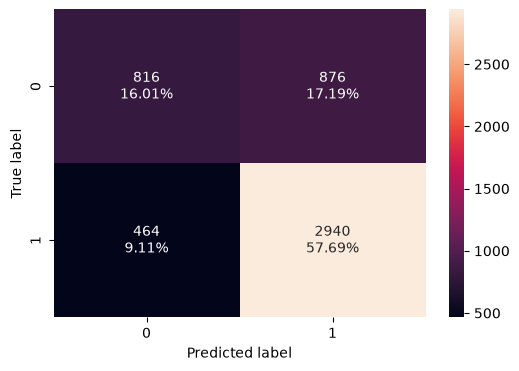

In [70]:
print("Confusion Matrix for the Validation Set")
confusion_matrix_sklearn(AB_Tuned, X_val, y_val)

Feature Importances

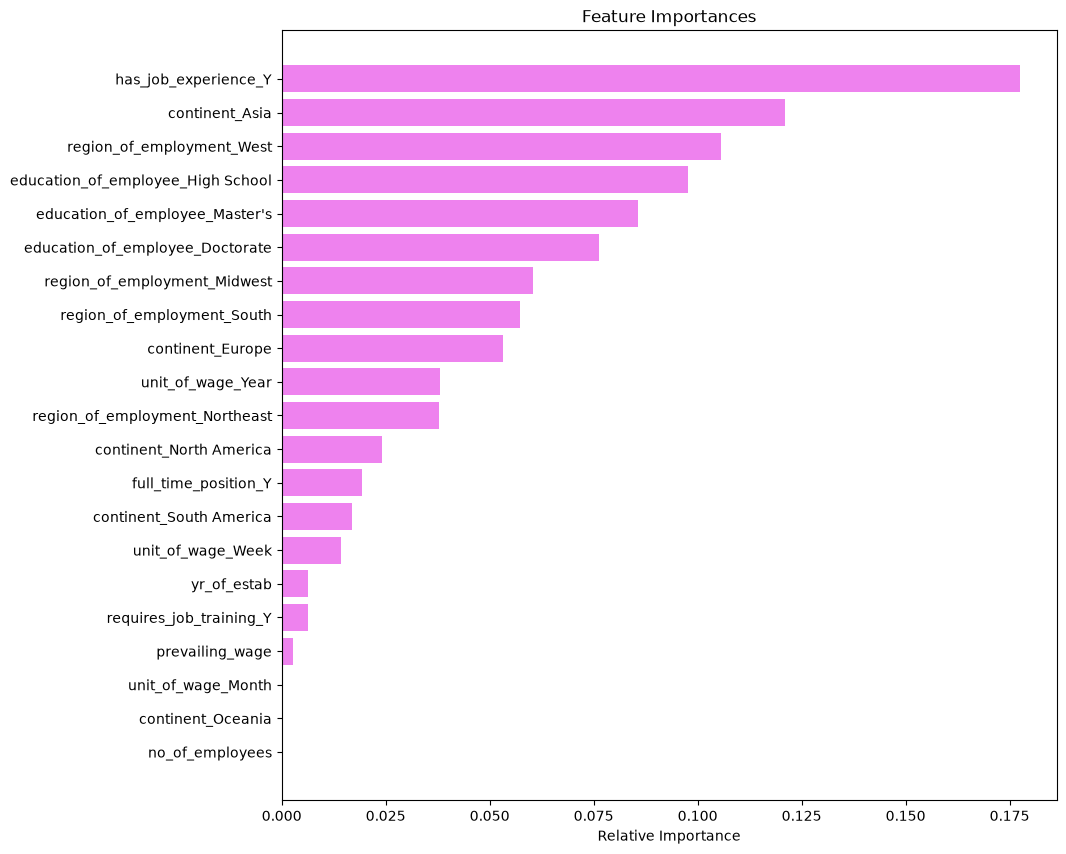

In [71]:
FeatureImportances(AB_Tuned)

### Hyperparameter Tuning - AdaBoost - GridSearchCV - Oversampled Data

In [72]:
%%time

# defining model
Model = AdaBoostClassifier(random_state=1)

# Parameter grid to pass in GridSearchCV
parameters = {
    "n_estimators": [25, 50, 75, 100],
    "learning_rate": [0.01, 0.1, 0.2,  1],
    "estimator": [
        DecisionTreeClassifier(max_depth=1, random_state=1),
        DecisionTreeClassifier(max_depth=2, random_state=1),
        DecisionTreeClassifier(max_depth=3, random_state=1),
    ],
}

#Calling GridSearchCV
AB_Tuned_GSCV = GridSearchCV(estimator=Model, param_grid=parameters, n_jobs = -1, scoring=scorer, cv=5)

#Fitting parameters in GridSearchCV
AB_Tuned_GSCV.fit(X_train_over, y_train_over)

print("Best parameters are {} with CV score={}:" .format(AB_Tuned_GSCV.best_params_,AB_Tuned_GSCV.best_score_))

# Performance - Training Set 
AB_Tuned_GSCV_df_perf_train_over = model_performance_classification_sklearn(
    AB_Tuned_GSCV, X_train_over, y_train_over)
AB_Tuned_GSCV_df_perf_train_over["Model"] = "AB_Tuned_GSCV" + "_train_over"
AB_Tuned_GSCV_df_perf_train_over.set_index("Model", inplace=True)

# Performance - Validation Set
AB_Tuned_GSCV_df_perf_val_over = model_performance_classification_sklearn(
    AB_Tuned_GSCV, X_val, y_val)
AB_Tuned_GSCV_df_perf_val_over["Model"] = "AB_Tuned_GSCV" + "_val_over"
AB_Tuned_GSCV_df_perf_val_over.set_index("Model", inplace=True)

# Performance
AB_Tuned_GSCV_df_perf_over = pd.concat([AB_Tuned_GSCV_df_perf_train_over, AB_Tuned_GSCV_df_perf_val_over], axis=0)
print(AB_Tuned_GSCV_df_perf_over)
print("_" * 60)


Best parameters are {'estimator': DecisionTreeClassifier(max_depth=1, random_state=1), 'learning_rate': 1, 'n_estimators': 100} with CV score=0.8117502001557095:
                          Accuracy  Recall  Precision    F1
Model                                                      
AB_Tuned_GSCV_train_over     0.800   0.871      0.762 0.813
AB_Tuned_GSCV_val_over       0.737   0.864      0.770 0.814
____________________________________________________________
CPU times: total: 5.3 s
Wall time: 28.6 s


**Best practices for hyperparameter tuning in Random Forest:**


`n_estimators`:

* Start with a specific number (50 is used in general) and increase in steps: 50, 75, 100, 125
* Higher values generally improve performance but increase training time
* Use 100-150 for large datasets or when variance is high


`min_samples_leaf`:

* Try values like: 1, 2, 4, 5, 10
* Higher values reduce model complexity and help prevent overfitting
* Use 1–2 for low-bias models, higher (like 5 or 10) for more regularized models
* Works well in noisy datasets to smooth predictions


`max_features`:

* Try values: `"sqrt"` (default for classification), `"log2"`, `None`, or float values (e.g., `0.3`, `0.5`)
* `"sqrt"` balances between diversity and performance for classification tasks
* Lower values (e.g., `0.3`) increase tree diversity, reducing overfitting
* Higher values (closer to `1.0`) may capture more interactions but risk overfitting


`max_samples` (for bootstrap sampling):

* Try float values between `0.5` to `1.0` or fixed integers
* Use `0.6–0.9` to introduce randomness and reduce overfitting
* Smaller values increase diversity between trees, improving generalization

---

### Hyperparameter Tuning - Random Forest - RandomizedSearchCV - Oversampled Data

In [73]:
%%time
# Choose the type of classifier.
Model = RandomForestClassifier(random_state=1)

# Grid of parameters to choose from
parameters = {
    "n_estimators": [50, 75, 100, 125],
    "min_samples_leaf": [1, 2, 4, 5, 10],
    "max_features": [0.3, 0.5, "sqrt", "log2", "auto"],
    "max_samples": [0.6, 0.8, 0.9, None],
}

#Calling RandomizedSearchCV
RF_Tuned_RSCV = RandomizedSearchCV(estimator=Model, param_distributions=parameters, n_jobs = -1, n_iter=50, scoring=scorer, cv=5, random_state=1)

# Fit the best algorithm to the data.
RF_Tuned_RSCV.fit(X_train_over, y_train_over)

print("Best parameters are {} with CV score={}:" .format(RF_Tuned_RSCV.best_params_,RF_Tuned_RSCV.best_score_))


Best parameters are {'n_estimators': 125, 'min_samples_leaf': 4, 'max_samples': 0.6, 'max_features': 'sqrt'} with CV score=0.8186326395445043:
CPU times: total: 5.03 s
Wall time: 26.8 s


Model based on the best parameters obtained by randomized serach cross validation

In [74]:
RF_Tuned = RandomForestClassifier(random_state=1,
                                  n_estimators=125,
                                  min_samples_leaf=4,
                                  max_samples=0.6,
                                  max_features='sqrt')
RF_Tuned.fit(X_train_over, y_train_over)
# Performance - Training Set
RF_Tuned_df_perf_train_over = model_performance_classification_sklearn(
    RF_Tuned, X_train_over, y_train_over
)
RF_Tuned_df_perf_train_over["Model"] = "RF_Tuned" + "_train_over"
RF_Tuned_df_perf_train_over.set_index("Model", inplace=True)

# Performance - Validation Set
RF_Tuned_df_perf_val_over = model_performance_classification_sklearn(
    RF_Tuned, X_val, y_val
)
RF_Tuned_df_perf_val_over["Model"] = "RF_Tuned" + "_val_over"
RF_Tuned_df_perf_val_over.set_index("Model", inplace=True)

# Performance
RF_Tuned_df_perf_over = pd.concat(
    [RF_Tuned_df_perf_train_over, RF_Tuned_df_perf_val_over], axis=0
)
print(RF_Tuned_df_perf_over)
print("_" * 60)

                     Accuracy  Recall  Precision    F1
Model                                                 
RF_Tuned_train_over     0.840   0.890      0.810 0.848
RF_Tuned_val_over       0.752   0.858      0.789 0.822
____________________________________________________________


Confusion Matrix on the Validation Set

Confusion Matrix for the Validation Set


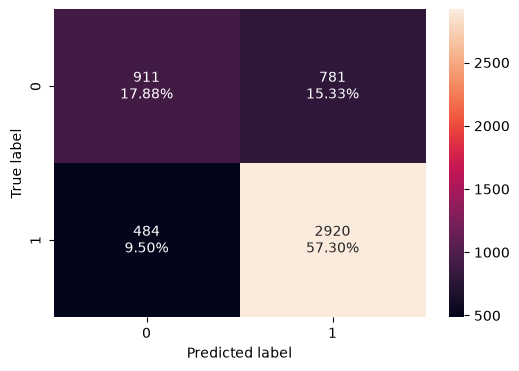

In [75]:
print("Confusion Matrix for the Validation Set")
confusion_matrix_sklearn(RF_Tuned, X_val, y_val)

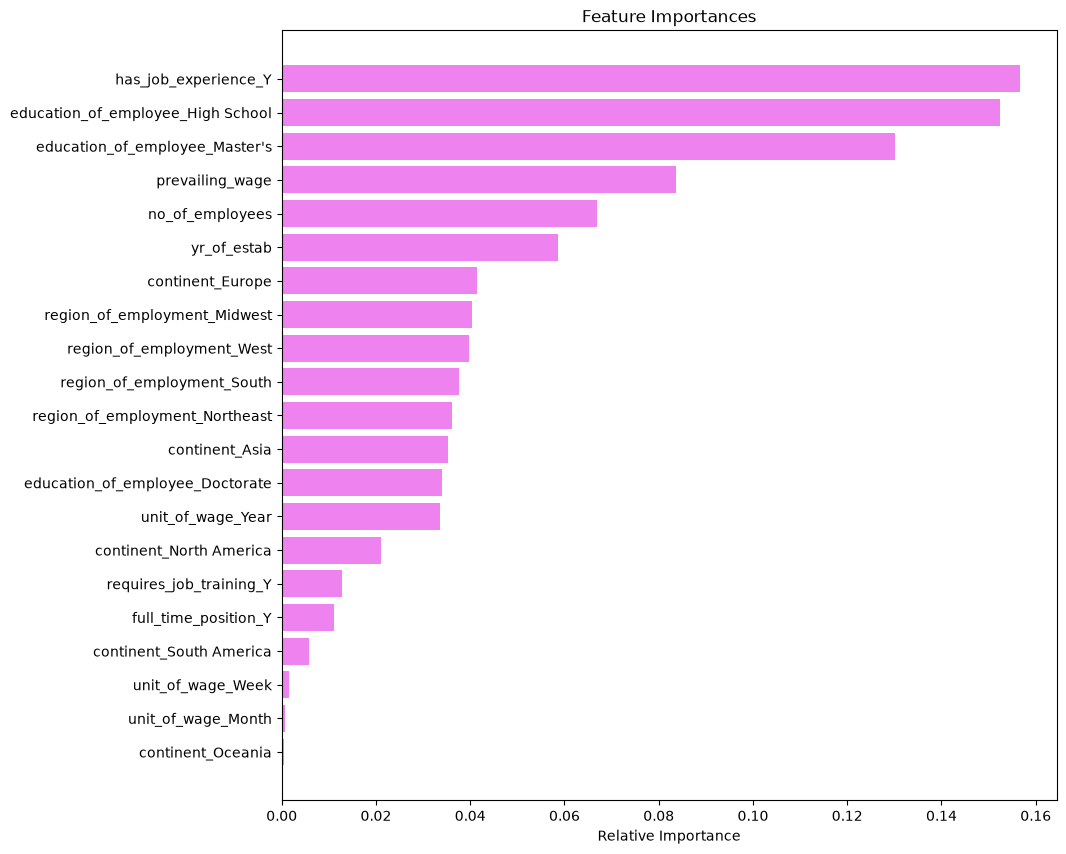

In [76]:
FeatureImportances(RF_Tuned)

**Best practices for hyperparameter tuning in Gradient Boosting:**

`n_estimators`:

* Start with 100 (default) and increase: 100, 200, 300, 500
* Typically, higher values lead to better performance, but they also increase training time
* Use 200–500 for larger datasets or complex problems
* Monitor validation performance to avoid overfitting, as too many estimators can degrade generalization


`learning_rate`:

* Common values to try: 0.1, 0.05, 0.01, 0.005
* Use lower values (e.g., 0.01 or 0.005) if you are using many estimators (e.g., > 200)
* Higher learning rates (e.g., 0.1) can be used with fewer estimators for faster convergence
* Always balance the learning rate with `n_estimators` to prevent overfitting or underfitting


`subsample`:

* Common values: 0.7, 0.8, 0.9, 1.0
* Use a value between `0.7` and `0.9` for improved generalization by introducing randomness
* `1.0` uses the full dataset for each boosting round, potentially leading to overfitting
* Reducing `subsample` can help reduce overfitting, especially in smaller datasets


`max_features`:

* Common values: `"sqrt"`, `"log2"`, or float (e.g., `0.3`, `0.5`)
* `"sqrt"` (default) works well for classification tasks
* Lower values (e.g., `0.3`) help reduce overfitting by limiting the number of features considered at each split

---

### Hyperparameter Tuning - Gradient Boosting - RandomizedSearchCV - Oversampled Data

In [77]:
%%time

#Creating pipeline
Model = GradientBoostingClassifier(random_state=1)

#Parameter grid to pass in RandomSearchCV
parameters = {
    "init": [AdaBoostClassifier(random_state=1),DecisionTreeClassifier(random_state=1)],
    "n_estimators":[100, 200, 300, 500],
    "learning_rate": [0.01, 0.1, 0.2, 1],
    "subsample":[0.7, 0.8, 0.9],
    "max_features":[0.5,0.7],
}

#Calling RandomizedSearchCV
GB_Tuned_RSCV = RandomizedSearchCV(estimator=Model, param_distributions=parameters, n_iter=50, scoring=scorer, cv=5, random_state=1, n_jobs = -1)

# Fit the best algorithm to the data.
GB_Tuned_RSCV.fit(X_train_over, y_train_over)

print("Best parameters are {} with CV score={}:" .format(GB_Tuned_RSCV.best_params_,GB_Tuned_RSCV.best_score_))


Best parameters are {'subsample': 0.9, 'n_estimators': 200, 'max_features': 0.5, 'learning_rate': 0.1, 'init': AdaBoostClassifier(random_state=1)} with CV score=0.8161123277442954:
CPU times: total: 7.42 s
Wall time: 1min 6s


Model based on the best parameters obtained by randomized serach cross validation

In [78]:
GB_Tuned = GradientBoostingClassifier(
    random_state=1,
    subsample=0.8,
    n_estimators=200,
    max_features=0.7,
    learning_rate=0.1,
    init=AdaBoostClassifier(random_state=1),
)
GB_Tuned.fit(X_train_over, y_train_over)
# Performance - Training Set
GB_Tuned_df_perf_train_over = model_performance_classification_sklearn(
    GB_Tuned, X_train_over, y_train_over
)
GB_Tuned_df_perf_train_over["Model"] = "GB_Tuned" + "_train_over"
GB_Tuned_df_perf_train_over.set_index("Model", inplace=True)

# Performance - Validation Set
GB_Tuned_df_perf_val_over = model_performance_classification_sklearn(
    GB_Tuned, X_val, y_val
)
GB_Tuned_df_perf_val_over["Model"] = "GB_Tuned" + "_val_over"
GB_Tuned_df_perf_val_over.set_index("Model", inplace=True)

# Performance
GB_Tuned_df_perf_over = pd.concat(
    [GB_Tuned_df_perf_train_over, GB_Tuned_df_perf_val_over], axis=0
)
print(GB_Tuned_df_perf_over)
print("_" * 60)

                     Accuracy  Recall  Precision    F1
Model                                                 
GB_Tuned_train_over     0.821   0.872      0.791 0.830
GB_Tuned_val_over       0.752   0.859      0.788 0.822
____________________________________________________________


Confusion Matrix on the Validation Set

Confusion Matrix on the Validation Set


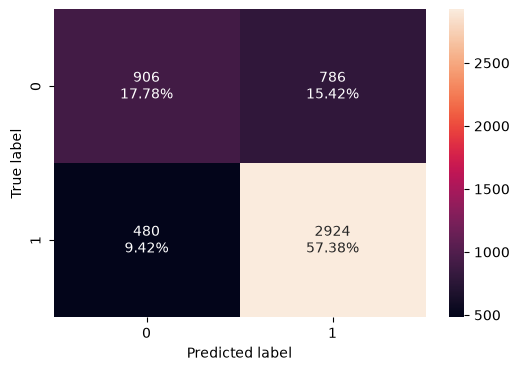

In [79]:
print('Confusion Matrix on the Validation Set')
confusion_matrix_sklearn(GB_Tuned, X_val, y_val)

Feature Importances

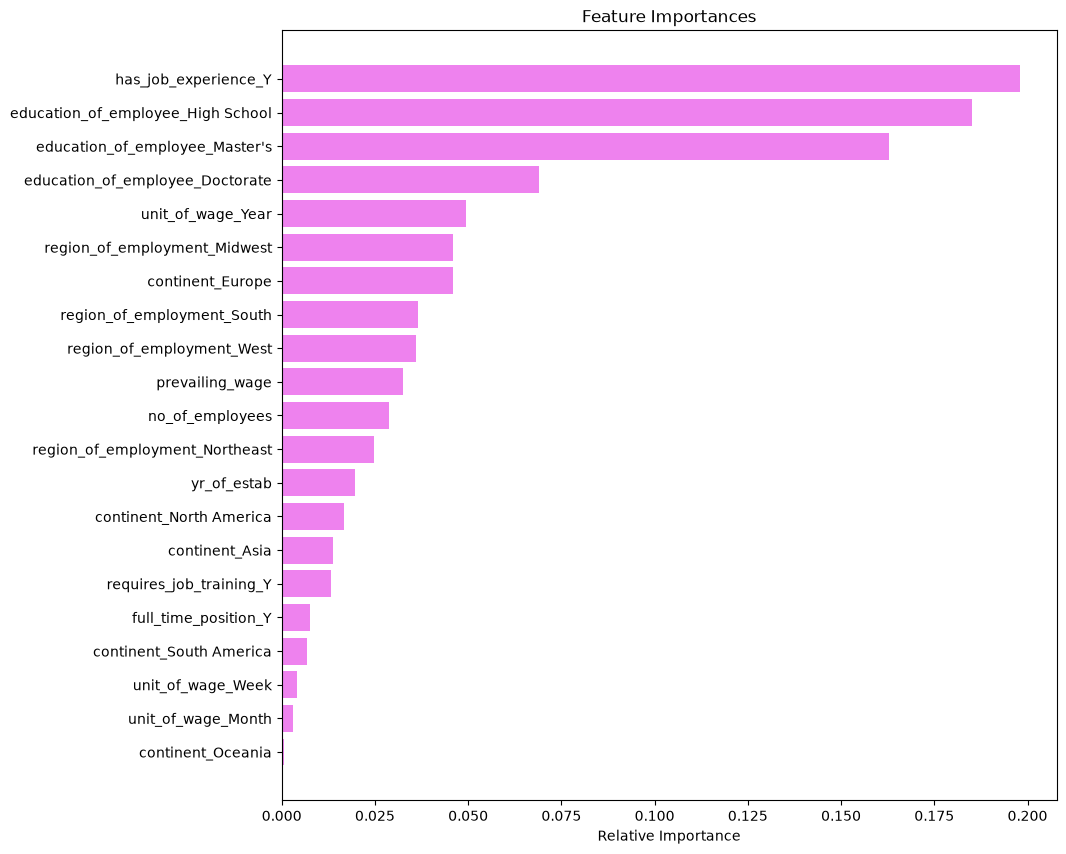

In [80]:
FeatureImportances(GB_Tuned)

**Best practices for hyperparameter tuning in XGBoost:**

`n_estimators`:

* Start with 50 and increase in steps: 50,75,100,125.
* Use more estimators (e.g., 150-250) when using lower learning rates
* Monitor validation performance
* High values improve learning but increase training time

`subsample`:

* Common values: 0.5, 0.7, 0.8, 1.0
* Use `0.7–0.9` to introduce randomness and reduce overfitting
* `1.0` uses the full dataset in each boosting round; may overfit on small datasets
* Values < 0.5 are rarely useful unless dataset is very large

`gamma`:

* Try values: 0 (default), 1, 3, 5, 8
* Controls minimum loss reduction needed for a split
* Higher values make the algorithm more conservative (i.e., fewer splits)
* Use values > 0 to regularize and reduce overfitting, especially on noisy data


`colsample_bytree`:

* Try values: 0.3, 0.5, 0.7, 1.0
* Fraction of features sampled per tree
* Lower values (e.g., 0.3 or 0.5) increase randomness and improve generalization
* Use `1.0` when you want all features considered for every tree


`colsample_bylevel`:

* Try values: 0.3, 0.5, 0.7, 1.0
* Fraction of features sampled at each tree level (i.e., per split depth)
* Lower values help in regularization and reducing overfitting
* Often used in combination with `colsample_bytree` for fine control over feature sampling

---

### Hyperparameter Tuning - XGBoost - RandomizedSearchCV - Oversampled Data

In [81]:
%%time

#Creating pipeline
Model = XGBClassifier(random_state=1)

#Parameter grid to pass in RandomSearchCV
parameters = {
    "n_estimators"     : [50, 75, 100, 125],
    "learning_rate"    : [0.01, 0.1, 0.2, 1],
    "subsample"        : [0.7, 0.8, 0.9],
    "gamma"            : [0,1,3,5,8],
    "colsample_bytree" : [0.3,0.5,0.7,1.0],
    "colsample_bylevel": [0.3,0.5,0.7,1.0]
}

#Calling RandomizedSearchCV
XGB_Tuned_RSCV = RandomizedSearchCV(estimator=Model, param_distributions=parameters, n_iter=50, scoring=scorer, cv=5, random_state=1, n_jobs = -1)

# Fit the best algorithm to the data.
XGB_Tuned_RSCV.fit(X_train_over, y_train_over)

print("Best parameters are {} with CV score={}:" .format(XGB_Tuned_RSCV.best_params_,XGB_Tuned_RSCV.best_score_))



Best parameters are {'subsample': 0.7, 'n_estimators': 100, 'learning_rate': 0.1, 'gamma': 1, 'colsample_bytree': 0.5, 'colsample_bylevel': 0.5} with CV score=0.6578551051191551:
CPU times: total: 10.1 s
Wall time: 14.9 s


Model based on the best parameters obtained by randomized serach cross validation

In [82]:
XGB_Tuned = XGBClassifier(random_state=1,
                          subsample=0.8,
                          n_estimators=125,
                          learning_rate=0.01,
                          gamma=0,
                          colsample_bytree=0.5,
                          colsample_bylevel=1.0)


# Fit the best algorithm to the data.
XGB_Tuned.fit(X_train_over, y_train_over)

# Performance - Training Set

XGB_Tuned_df_perf_train_over = model_performance_classification_sklearn(
    XGB_Tuned, X_train_over, y_train_over
)
XGB_Tuned_df_perf_train_over["Model"] = "XGB_Tuned" + "_train_over"
XGB_Tuned_df_perf_train_over.set_index("Model", inplace=True)

# Performance - Validation Set
XGB_Tuned_df_perf_val_over = model_performance_classification_sklearn(
    XGB_Tuned, X_val, y_val
)
XGB_Tuned_df_perf_val_over["Model"] = "XGB_Tuned" + "_val_over"
XGB_Tuned_df_perf_val_over.set_index("Model", inplace=True)

# Performance
XGB_Tuned_df_perf_over = pd.concat(
    [XGB_Tuned_df_perf_train_over, XGB_Tuned_df_perf_val_over], axis=0
)
print(XGB_Tuned_df_perf_over)
print("_" * 60)

                      Accuracy  Recall  Precision    F1
Model                                                  
XGB_Tuned_train_over     0.811   0.876      0.776 0.823
XGB_Tuned_val_over       0.747   0.867      0.779 0.821
____________________________________________________________


Confusion Matrix on the Validation Set

Confusion Matrix on the Validation Set


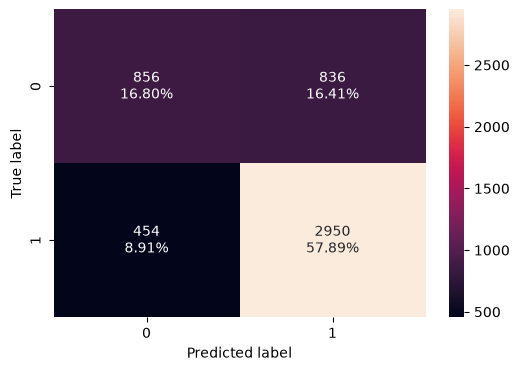

In [83]:
print("Confusion Matrix on the Validation Set")
confusion_matrix_sklearn(XGB_Tuned, X_val, y_val)

Feature Importances

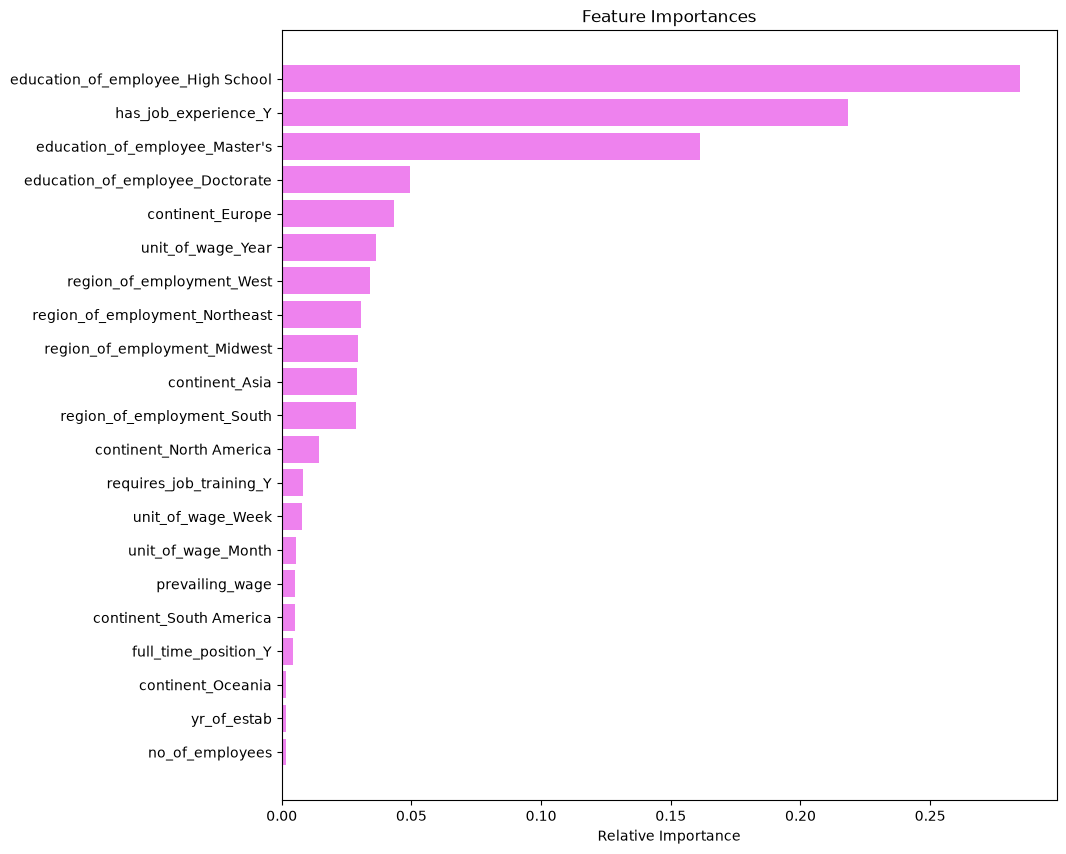

In [84]:
FeatureImportances(XGB_Tuned)

# Model Performance Summary and Final Model Selection

#### Summary of the performance of the models

In [85]:
# Models Performance Summary

Models_Performance_df = pd.concat([
    AB_Tuned_df_perf_over,
    RF_Tuned_df_perf_over,
    GB_Tuned_df_perf_over,
    XGB_Tuned_df_perf_over], axis=0)
print(Models_Performance_df)

                      Accuracy  Recall  Precision    F1
Model                                                  
AB_Tuned_train_over      0.800   0.871      0.762 0.813
AB_Tuned_val_over        0.737   0.864      0.770 0.814
RF_Tuned_train_over      0.840   0.890      0.810 0.848
RF_Tuned_val_over        0.752   0.858      0.789 0.822
GB_Tuned_train_over      0.821   0.872      0.791 0.830
GB_Tuned_val_over        0.752   0.859      0.788 0.822
XGB_Tuned_train_over     0.811   0.876      0.776 0.823
XGB_Tuned_val_over       0.747   0.867      0.779 0.821


#### Model With Best Perfomance

In [86]:
# Best Model Performance
Best_Model = XGB_Tuned

# Performance - Training Set
Best_Model_df_perf_train_over = model_performance_classification_sklearn(
    Best_Model, X_train_over, y_train_over
)
Best_Model_df_perf_train_over["Best Model"] = "Best_Model" + "_train"
Best_Model_df_perf_train_over.set_index("Best Model", inplace=True)

# Performance - Validation Set
Best_Model_df_perf_val_over = model_performance_classification_sklearn(
    Best_Model, X_val, y_val
)
Best_Model_df_perf_val_over["Best Model"] = "Best_Model" + "_val"
Best_Model_df_perf_val_over.set_index("Best Model", inplace=True)

# Performance - Test Set
Best_Model_df_perf_test_over = model_performance_classification_sklearn(
    Best_Model, X_test, y_test
)
Best_Model_df_perf_test_over["Best Model"] = "Best_Model" + "_test"
Best_Model_df_perf_test_over.set_index("Best Model", inplace=True)

# Performance
Best_Model_df_perf_over = pd.concat(
    [
        Best_Model_df_perf_train_over,
        Best_Model_df_perf_val_over,
        Best_Model_df_perf_test_over,
    ],
    axis=0,
)
print(Best_Model_df_perf_over)
print("_" * 60)

                  Accuracy  Recall  Precision    F1
Best Model                                         
Best_Model_train     0.811   0.876      0.776 0.823
Best_Model_val       0.747   0.867      0.779 0.821
Best_Model_test      0.741   0.870      0.772 0.818
____________________________________________________________


#### Confusion Matrix on the Test Data

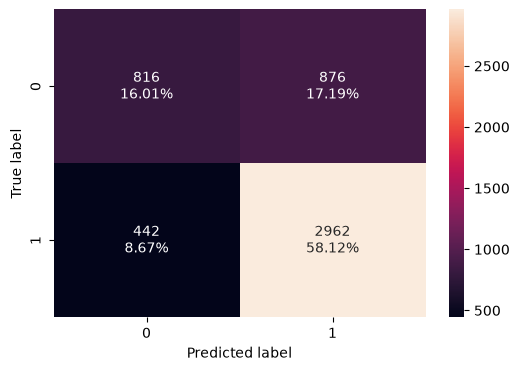

In [87]:
# Confusion Matrix on Test Data
confusion_matrix_sklearn(Best_Model, X_test, y_test)

# Feature Importance

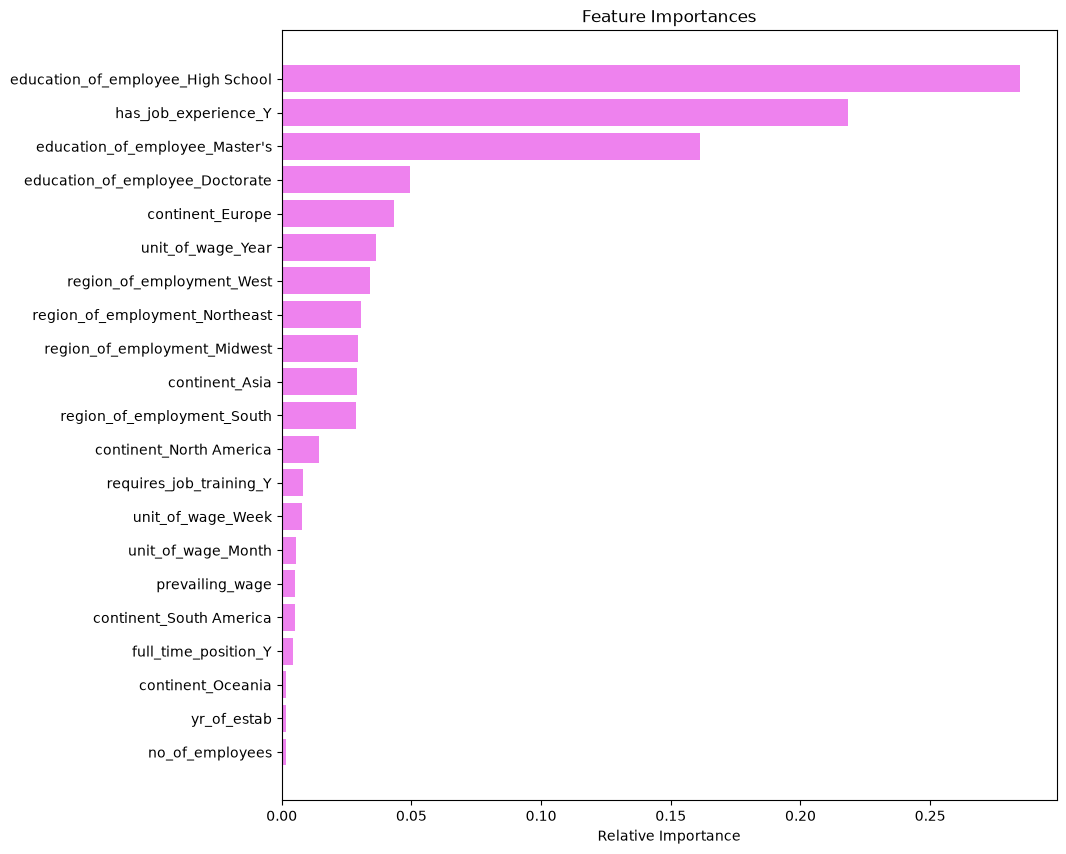

In [88]:
FeatureImportances(Best_Model)

## Actionable Insights and Recommendations

### Modeling Observations

About modeling:

1. Several ensemble models are developed and the performance of each model is evaluated.
2. Models on the original data, oversampled data and undersampled data are performed. 
3. Many of the models showed some overfitting without hyperparameter tuning.
4. However, majority of the models showed slightly better performance with oversampled data. 
5. Hence, Hyperparameter tuning is performed for RandomForest, Adaboost, Gradient Boost and XGBoost models on oversampled data.
6. Since the objective is to recommend a suitable profile for the applicants for whom the visa should be certified or denied based on the drivers that significantly influence the case status,
   probably both recall and precison are important. Hence, f1_score is chosen as the performance metric.
7. Keeping the computational time within reasonable limits, RandomizedSearchCV is used for hyperparameter tuning with crossvalidation.
8. Almost all the tuned models yielded similar performances on the train and validation f1_scores, ranging between 0.813-0.848.
9. Overfitting is significantly reduced. Adaboost and XGBoost models showed least overfitting between training and validation sets.
10. XGBoost model is chosen as the final model as performance metrics are is slightly better and computational time is lower.
11. This model generalizes very well indicated by  0.823, 0.820, 0.818 as f1_scores of train, validation and test sets respectively.

### Insights and Recommendations

1. Education level and prior work experience are the most significant factors in the prediction of whether VISA is 'Certified or Denied'.
2. Continent of the applicants also one of the influencial parameters.
3. year of establishment and no.of employees are the least influencing factors.
4. These insights from feature importances are consistent with those observed in EDA.
5. While the relative importance of these features is understand, it is not clearly understood the direction of influence whether a particular feature influences positively or negatively.

<font size=6 color='blue'>Power Ahead</font>
___